# <font color='#2E86C1' size=6>**Classification modelling: will the customer buy again within 90 days?**</font>

**Workflow:** [01 Data cleaning](01_data_cleaning.ipynb) → [02 Customer table](02_customer_table.ipynb) → [03 Missing values](03_missing_values.ipynb) → [04 Outliers](04_outlier_detection.ipynb) → [05 Pipeline and models](05_pipeline_and_models.ipynb) → [06 Feature engineering and selection](06_feature_engineering_selection.ipynb) → **07 Classification modelling**

**Scope.** The modelling step of the classification task (`repeat_purchase_90d`), from a baseline to an explained final model:

| To-do | Section |
|---|---|
| Establish baseline model | 1 |
| Build preprocessing pipeline (imputation, encoding, scaling) | 2 |
| Logistic regression, k-NN, decision tree, random forest, extra trees, histogram gradient boosting, XGBoost | 3 |
| Hyperparameter tuning (Optuna, nested temporal CV) | 4 |
| Compare evaluation metrics | 5 |
| Select final model (+ one evaluation on the locked test set) | 6 |
| Evaluate classification threshold and business implications | 7 |
| Classification explainability (SHAP global, SHAP / LIME local) | 8 |
| Feature importance analysis | 9 |
| Interpret important drivers of customer return | 10 |

**Rules carried over from the earlier notebooks** (notebook 01, sections 6–7):

- everything is fitted, compared, tuned and chosen on the **development set** with the 5 **expanding-window temporal folds** (90-day gap), exactly like `python main.py`;
- the **locked test set** (latest 20 % of purchases, 2023-06 → 2025-02) is used **once**, for the final model only (section 6), and afterwards only to *describe* that model (sections 7–8), never to choose anything;
- two options are compared **fold by fold**; a difference is *decisive* when it is more than 2 standard errors from zero. The pipeline changes only for a decisive gain with a sensible reason; otherwise the current or simpler option stays.

Every function that exists in the pipeline (`src/`, `classification/`) is imported, not redefined, so this notebook and `main.py` run the same code.

<a class="anchor" id="toc"></a>
## Table of contents

0. [Setup](#setup)
1. [Baseline models](#baseline)
2. [Preprocessing pipeline](#preprocessing)
3. [Candidate models](#candidates)
4. [Hyperparameter tuning](#tuning)
5. [Comparing evaluation metrics](#comparison)
6. [Final model and the locked test set](#final)
7. [Classification threshold and business implications](#threshold)
8. [Explainability: SHAP and LIME](#explainability)
9. [Feature importance analysis](#importance)
10. [Drivers of customer return](#drivers)
11. [Summary](#summary)

# <font color='#2E86C1' size=6>**0. Setup**</font> <a class="anchor" id="setup"></a>

[Back to TOC](#toc)

In [1]:
import os
import re
import sys
import time
import warnings
from pathlib import Path

# run from the project root, whether Jupyter was started there or in notebooks/
ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import sklearn
import yaml
from lime.lime_tabular import LimeTabularExplainer
from scipy.stats import spearmanr
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score, brier_score_loss, confusion_matrix,
    f1_score, log_loss, precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,
)

from classification.evaluate import holdout_report, predict_for_report
from classification.model import build_model
from src.evaluate import cross_validate_with_oof, greater_is_better, paired_comparison, temporal_folds
from src.pipeline import build_pipeline, prepare_task_data
from src.tuning import nested_cross_validate, tune_pipeline

warnings.filterwarnings("ignore")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)
sklearn.set_config(display="diagram")

with open("config.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)
TASK = "classification"
task_cfg, data_cfg = config[TASK], config["data"]
DATE = data_cfg["date_column"]
SEED = config["preprocessing"].get("random_state", 42)
METRIC = task_cfg["selection_metric"]                       # accuracy: every comparison and the tuning
CURRENT_MODEL = task_cfg["model"]["type"]                   # the model config.yaml currently uses

# the same load -> validate -> clean -> history fill -> locked test split as main.py
data = prepare_task_data(config, TASK)
recipe = data["preprocessing_config"]
X_dev, X_test = data["X_dev"], data["X_test"]
y_dev, y_test = data["y_dev"].astype(int), data["y_test"].astype(int)
extras_dev, extras_test = data["extras_dev"], data["extras_test"]
folds = temporal_folds(extras_dev[DATE], config["cv"]["n_splits"], config["cv"]["gap_days"])

print(f"development set: {len(X_dev):,} purchases ({extras_dev[DATE].min():%Y-%m-%d} -> {extras_dev[DATE].max():%Y-%m-%d}), "
      f"repurchase rate {y_dev.mean():.3f}")
print(f"locked test set: {len(X_test):,} purchases ({extras_test[DATE].min():%Y-%m-%d} -> {extras_test[DATE].max():%Y-%m-%d}), "
      f"repurchase rate {y_test.mean():.3f}")
print(f"temporal folds:  {[(len(t), len(v)) for t, v in folds]}  (train rows, validation rows)")

development set: 5,024 purchases (2015-07-11 -> 2023-03-18), repurchase rate 0.550
locked test set: 1,286 purchases (2023-06-19 -> 2025-02-15), repurchase rate 0.603
temporal folds:  [(750, 838), (1516, 837), (2347, 837), (3185, 837), (3936, 837)]  (train rows, validation rows)


In [2]:
# every metric is reported; `accuracy` (config.yaml -> classification.selection_metric) decides.
# precision / recall / F1 are for class 1 (the customer returns). Brier and log loss: lower is better.
SCORING = {
    "accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy", "precision": "precision",
    "recall": "recall", "f1": "f1", "roc_auc": "roc_auc", "average_precision": "average_precision",
    "brier": "neg_brier_score", "log_loss": "neg_log_loss",
}
LOWER_IS_BETTER = [m for m, s in SCORING.items() if not greater_is_better(s)]

# the candidate models with sensible untuned settings (section 3), all from the task's registry
MODELS = ["logistic_regression", "knn", "decision_tree", "random_forest", "extra_trees",
          "hist_gradient_boosting", "xgboost"]
BASE_MODELS = {
    "logistic_regression": {"type": "logistic_regression", "params": {"max_iter": 2000}},
    "knn": {"type": "knn", "params": {"n_neighbors": 25}},
    "decision_tree": {"type": "decision_tree", "params": {"max_depth": 5, "random_state": SEED}},
    "random_forest": {"type": "random_forest", "params": {"n_estimators": 300, "min_samples_leaf": 5,
                                                          "n_jobs": -1, "random_state": SEED}},
    "extra_trees": {"type": "extra_trees", "params": {"n_estimators": 300, "min_samples_leaf": 5,
                                                      "n_jobs": -1, "random_state": SEED}},
    "hist_gradient_boosting": {"type": "hist_gradient_boosting", "params": {"random_state": SEED}},
    "xgboost": {"type": "xgboost", "params": {"n_estimators": 300, "learning_rate": 0.05, "max_depth": 4,
                                              "subsample": 0.8, "colsample_bytree": 0.8, "n_jobs": -1,
                                              "random_state": SEED, "eval_metric": "logloss"}},
}
TREE_MODELS = {"decision_tree", "random_forest", "extra_trees", "hist_gradient_boosting", "xgboost"}

# chart style: recessive grid and axes, one fixed colour per model (colour follows the model, never its rank)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY, INK = "#898781", "#52514e"
MODEL_COLORS = dict(zip(MODELS, PALETTE))
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "lines.linewidth": 2,
    "legend.frameon": False, "figure.dpi": 110, "font.size": 9,
})


def cv_with_oof(estimator):
    '''Temporal CV of a full estimator on every metric -> (fold scores, out-of-fold probabilities).'''
    return cross_validate_with_oof(estimator, X_dev, y_dev, folds, SCORING, predict_for_report)


def summary_table(results: dict, metrics=tuple(SCORING)) -> pd.DataFrame:
    '''One row per model: mean validation score of every metric, the std of the selection metric and
    the overfitting gap (train - validation accuracy).'''
    rows = []
    for name, fold_scores in results.items():
        row = {"model": name, **{m: fold_scores[f"validation_{m}"].mean() for m in metrics}}
        row[f"{METRIC}_std"] = fold_scores[f"validation_{METRIC}"].std(ddof=1)
        row[f"train_{METRIC}"] = fold_scores[f"train_{METRIC}"].mean()
        row["overfit_gap"] = row[f"train_{METRIC}"] - row[METRIC]
        rows.append(row)
    return pd.DataFrame(rows).set_index("model").sort_values(METRIC, ascending=False)


def paired_table(results: dict, reference: str, metric: str = METRIC) -> pd.DataFrame:
    '''Every model vs `reference`, fold by fold (positive = the model is better than the reference).'''
    higher = greater_is_better(SCORING[metric])
    ref = results[reference][f"validation_{metric}"]
    rows = [{"model": name, **paired_comparison(fs[f"validation_{metric}"], ref, higher)}
            for name, fs in results.items() if name != reference]
    return pd.DataFrame(rows).set_index("model").sort_values("mean_advantage", ascending=False)


def drop_features(recipe: dict, names) -> dict:
    '''The recipe without `names` (notebook 06, section 9). An imputation setting that reads a dropped
    column goes with it: a row limit or fit-row rule can't use a column the recipe no longer has.'''
    names = set(names)
    reads_dropped = lambda setting: any(re.search(rf"\b{name}\b", str(setting)) for name in names)
    imputation = recipe.get("imputation", {})
    row_bounds = {column: {side: limit for side, limit in limits.items() if not reads_dropped(limit)}
                  for column, limits in imputation.get("row_bounds", {}).items() if column not in names}
    kept = lambda setting: {column: spec for column, spec in imputation.get(setting, {}).items()
                            if column not in names and not reads_dropped(spec)}
    return {**recipe, **{key: [c for c in recipe.get(key, []) if c not in names]
                         for key in ["numeric_features", "categorical_features", "flag_features", "mnar_indicator_sources"]},
            "imputation": {**imputation, "row_bounds": {c: limits for c, limits in row_bounds.items() if limits},
                           "fit_rows": kept("fit_rows"), "column_imputers": kept("column_imputers")}}


def fmt(table: pd.DataFrame, digits: int = 4):
    return table.round(digits)

# <font color='#2E86C1' size=6>**1. Baseline models**</font> <a class="anchor" id="baseline"></a>

A model is only useful if it beats something simpler. Three baselines, each scored on the same temporal folds and metrics as every model later:

| Baseline | What it does | Learns from the training rows |
|---|---|---|
| **Majority class** (`DummyClassifier`, `strategy="prior"`) | everyone returns (the majority class); its probability is the training repurchase rate | 1 number |
| **Recency rule** | *"the customer returns if they already bought in the previous 90 days"* (`purchase_count_90d ≥ 1`); its probability is the repurchase rate of each group of the rule | 2 numbers |
| **RFM logistic regression** | logistic regression on the three classic RFM columns only: recency (`days_since_previous_purchase`), frequency (`prior_purchase_count`), monetary (`prior_total_spend`), with the same imputation and scaling | 4 coefficients |

The majority class is the floor; the recency rule is what a sales team would do without a model; the RFM model shows how much the remaining 32 columns and the full recipe add.


[Back to TOC](#toc)

In [3]:
class RecencyRule(ClassifierMixin, BaseEstimator):
    '''"Bought at least once in the previous 90 days" -> returns. The probability of each rule group is
    its repurchase rate in the training rows, so the rule can be scored on ROC-AUC, Brier and log loss too.'''

    def __init__(self, column="purchase_count_90d"):
        self.column = column

    def _group(self, X):
        return (pd.to_numeric(X[self.column], errors="coerce").fillna(0) > 0).to_numpy()

    def fit(self, X, y):
        group, y = self._group(X), np.asarray(y).astype(int)
        self.classes_ = np.array([0, 1])
        self.rate_ = {g: y[group == g].mean() for g in (False, True)}
        return self

    def predict_proba(self, X):
        p = np.where(self._group(X), self.rate_[True], self.rate_[False])
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


RFM = ["days_since_previous_purchase", "prior_purchase_count", "prior_total_spend"]
used_raw = recipe["numeric_features"] + recipe["categorical_features"] + recipe["flag_features"]
rfm_recipe = drop_features(recipe, [c for c in used_raw if c not in RFM])

BASELINES = {
    "dummy (majority class)": build_model({"type": "dummy", "params": {"strategy": "prior"}}),
    "recency rule": RecencyRule(),
    "RFM logistic regression": build_pipeline(rfm_recipe, build_model(BASE_MODELS["logistic_regression"])),
}
baseline_scores, baseline_oof = {}, {}
for name, estimator in BASELINES.items():
    baseline_scores[name], baseline_oof[name] = cv_with_oof(estimator)
baseline_table = summary_table(baseline_scores)
fmt(baseline_table)

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,brier,log_loss,accuracy_std,train_accuracy,overfit_gap
model,,,,,,,,,,,,
recency rule,0.6677,0.6627,0.6998,0.6939,0.6967,0.6627,0.6548,0.2211,0.6340,0.0212,0.6585,-0.0092
RFM logistic regression,0.6634,0.6447,0.6553,0.8280,0.7308,0.7557,0.8106,0.2162,0.6401,0.0366,0.6455,-0.0179
dummy (majority class),0.5530,0.5000,0.5530,1.0000,0.7117,0.5000,0.5530,0.2482,0.6895,0.0345,0.5532,0.0002


**Reading the baselines** (mean of the 5 temporal folds):

- **Majority class: accuracy 0.553**, ROC-AUC 0.5. This is the floor.
- **Recency rule: accuracy 0.668** (+0.115 over the floor) with no model at all: *"bought in the last 90 days"* already separates customers who return 70 % of the time from those who return 38 % of the time. Its ROC-AUC is only 0.663, because it sorts customers into just two groups.
- **RFM logistic regression: accuracy 0.663, ROC-AUC 0.756.** It ranks customers much better than the rule (+0.09 ROC-AUC), but at 0.5 it predicts "returns" too often (recall 0.83, precision 0.66).

**Bar to clear:** a full model must beat about **0.67 accuracy / 0.76 ROC-AUC**. Anything less adds nothing over a rule of thumb or three columns.

# <font color='#2E86C1' size=6>**2. Preprocessing pipeline: imputation, encoding, scaling**</font> <a class="anchor" id="preprocessing"></a>

The recipe was built and justified in notebooks 01–06 and lives in `config.yaml`; `build_pipeline()` (`src/pipeline.py`) puts `build_preprocessor()` and the model into **one** sklearn `Pipeline`, so every learned step is re-fitted on the training rows of each fold and nothing leaks from the validation rows:

| Step | Columns | What it does (fitted on training rows only) |
|---|---|---|
| **Before the pipeline** (rules, nothing learned) | all | placeholder tokens → `NaN`, schema validation, invalid values → `NaN`, consistency rules, exact recovery from identities, structural zeros + flags, gaps filled from the customer's **earlier** purchases |
| `numeric` | 26 amount, count and history columns | `RowBoundedImputer`: median learned without the structural zeros of first purchases, imputed values kept within the row's own limits → `StandardScaler` |
| `categorical` | 6 transaction categories | most-frequent imputation → target encoding (cross-fitted, unseen categories → overall rate) |
| `indicators` | `spend_365d` | `MissingIndicator` on the raw column, before imputation (its gap carries information) |
| `flags` | `is_first_purchase`, `has_gap_history` | passed through |


[Back to TOC](#toc)

In [4]:
example = build_pipeline(recipe, build_model(BASE_MODELS["logistic_regression"]))
display(example)

fitted_prep = clone(example).fit(X_dev, y_dev).named_steps["prep"]
feature_names = fitted_prep.get_feature_names_out()
shapes = pd.DataFrame({
    split: {"rows": len(X), "model columns": fitted_prep.transform(X).shape[1],
            "missing values after the recipe": int(np.isnan(fitted_prep.transform(X)).sum())}
    for split, X in {"development": X_dev, "locked test": X_test, "test.csv (Kaggle)": data["X_kaggle"]}.items()
}).T
display(shapes)
print(f"{len(feature_names)} model columns:", ", ".join(n.split("__", 1)[1] for n in feature_names))

,steps,"[('prep', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


,rows,model columns,missing values after the recipe
development,5024,35,0
locked test,1286,35,0
test.csv (Kaggle),986,35,0


35 model columns: net_total, total_tax, shipping_cost, global_discount_total, line_discount_total, cost, line_item_count, invoice_count_current_purchase, days_since_previous_purchase, customer_tenure_days, prior_purchase_count, prior_total_spend, prior_mean_purchase_value, prior_std_purchase_value, prior_min_purchase_value, prior_max_purchase_value, prior_mean_gap_days, prior_std_gap_days, purchase_count_30d, spend_30d, purchase_count_90d, spend_90d, purchase_count_180d, spend_180d, purchase_count_365d, spend_365d, payment_type, salesperson, commercial_zone, transport_method, warehouse, document_series, missingindicator_spend_365d, is_first_purchase, has_gap_history


### 2.1 Does the reduced feature list of notebook 06 help the candidate models?

Notebook 06 (section 10) found seven columns without signal for the classification (`global_discount_total`, `commercial_zone`, `warehouse`, `document_series`, `shipping_cost`, `invoice_count_current_purchase`, `is_first_purchase`) and asked for **one confirming ablation with the final models**, because its evidence came from logistic regression only. Here: full recipe vs recipe without those seven columns, for one linear and two tree-based models, untuned, on the same folds.

In [5]:
NB06_DROP = ["global_discount_total", "commercial_zone", "warehouse", "document_series", "shipping_cost",
             "invoice_count_current_purchase", "is_first_purchase"]
reduced_recipe = drop_features(recipe, NB06_DROP)

rows = []
for name in ["logistic_regression", "random_forest", "xgboost"]:
    full, _ = cv_with_oof(build_pipeline(recipe, build_model(BASE_MODELS[name])))
    reduced, _ = cv_with_oof(build_pipeline(reduced_recipe, build_model(BASE_MODELS[name])))
    for metric in [METRIC, "roc_auc"]:
        rows.append({"model": name, "metric": metric, "full recipe": full[f"validation_{metric}"].mean(),
                     "reduced recipe": reduced[f"validation_{metric}"].mean(),
                     **paired_comparison(reduced[f"validation_{metric}"], full[f"validation_{metric}"])})
ablation = pd.DataFrame(rows).set_index(["model", "metric"])
fmt(ablation)

full recipe  reduced recipe  mean_advantage      se  folds_a_better  n_folds  decisive
model               metric                                                                                          
logistic_regression accuracy       0.7078          0.7107          0.0029  0.0025               2        5     False
                    roc_auc        0.7728          0.7755          0.0026  0.0015               4        5     False
random_forest       accuracy       0.7083          0.7062         -0.0022  0.0020               1        5     False
                    roc_auc        0.7790          0.7782         -0.0009  0.0013               3        5     False
xgboost             accuracy       0.6914          0.6937          0.0024  0.0032               3        5     False
                    roc_auc        0.7609          0.7607         -0.0001  0.0015               3        5     False

**Verdict: keep the full recipe of `config.yaml`.** Without the seven columns, logistic regression gains +0.003 accuracy (2/5 folds) and +0.003 ROC-AUC (4/5 folds, 1.7 SE), XGBoost +0.002 accuracy, and the random forest loses −0.002. **No difference is decisive** in either direction, and the effect changes sign between model families. The rule therefore keeps the current (and `main.py`) recipe. Section 9 confirms the seven columns carry almost no signal, so removing them stays a parsimony option, not a performance gain.

# <font color='#2E86C1' size=6>**3. Candidate models**</font> <a class="anchor" id="candidates"></a>

Seven model families, each inside the same pipeline, with sensible untuned settings:

| Model | Why it is a candidate |
|---|---|
| Logistic regression | the current model (`config.yaml`); linear in log-odds, well calibrated, easy to explain |
| k-nearest neighbours (k = 25) | a non-parametric, distance-based reference (uses the scaled features) |
| Decision tree (depth 5) | the most interpretable non-linear model |
| Random forest (300 trees) | bagged trees: non-linear, interactions, robust to collinearity |
| Extra trees (300 trees) | more randomised trees: lower variance than the forest |
| Histogram gradient boosting | sklearn's boosted trees |
| XGBoost (300 trees, depth 4, η = 0.05) | regularised boosted trees |

Scores are the mean over the 5 temporal folds. `overfit_gap` = training accuracy − validation accuracy.


[Back to TOC](#toc)

In [6]:
untuned_scores, untuned_oof = {}, {}
for name in MODELS:
    untuned_scores[name], untuned_oof[name] = cv_with_oof(build_pipeline(recipe, build_model(BASE_MODELS[name])))
untuned_table = summary_table({**untuned_scores, "dummy (majority class)": baseline_scores["dummy (majority class)"]})
display(fmt(untuned_table))
print(f"Paired comparison on {METRIC} against the current model ({CURRENT_MODEL}):")
fmt(paired_table(untuned_scores, CURRENT_MODEL))

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,brier,log_loss,accuracy_std,train_accuracy,overfit_gap
model,,,,,,,,,,,,
extra_trees,0.7126,0.7078,0.7348,0.7546,0.7433,0.7850,0.8350,0.1903,0.5561,0.0199,0.7711,0.0585
random_forest,0.7083,0.7015,0.7243,0.7647,0.7429,0.7790,0.8270,0.1920,0.5612,0.0114,0.8504,0.1421
logistic_regression,0.7078,0.7088,0.7591,0.6962,0.7237,0.7728,0.8294,0.1941,0.5745,0.0155,0.7081,0.0003
knn,0.6928,0.6889,0.7209,0.7255,0.7222,0.7602,0.8052,0.1993,0.5926,0.0128,0.7029,0.0101
xgboost,0.6914,0.6924,0.7345,0.7010,0.7130,0.7609,0.8121,0.2041,0.5986,0.0205,0.8585,0.1672
hist_gradient_boosting,0.6832,0.6811,0.7181,0.7111,0.7114,0.7526,0.8075,0.2148,0.6471,0.0128,0.9352,0.2519
decision_tree,0.6515,0.6468,0.6857,0.6828,0.6836,0.6972,0.7514,0.2367,2.1989,0.0397,0.7378,0.0864
dummy (majority class),0.5530,0.5000,0.5530,1.0000,0.7117,0.5000,0.5530,0.2482,0.6895,0.0345,0.5532,0.0002


Paired comparison on accuracy against the current model (logistic_regression):


,mean_advantage,se,folds_a_better,n_folds,decisive
model,,,,,
extra_trees,0.0048,0.0042,4,5,False
random_forest,0.0005,0.0035,2,5,False
knn,-0.0151,0.0054,0,5,True
xgboost,-0.0165,0.0084,1,5,False
hist_gradient_boosting,-0.0246,0.0034,0,5,True
decision_tree,-0.0564,0.0119,0,5,True


**Untuned, nothing beats the current logistic regression.** Extra trees (0.713, +0.005, 4/5 folds) and the random forest (0.708) tie with it. k-NN (−0.015), histogram gradient boosting (−0.025) and the depth-5 tree (−0.056) are **decisively worse**. Every model clears the baselines except the single tree, which barely beats the recency rule.

The **overfitting gap** explains most of the ranking. The boosters and forests memorise the training rows with default settings (HGB train 0.94 → validation 0.68, XGBoost 0.86 → 0.69, forest 0.85 → 0.71), while logistic regression has no gap at all (0.708 / 0.708). So tuning (section 4) should mainly add regularisation.

# <font color='#2E86C1' size=6>**4. Hyperparameter tuning**</font> <a class="anchor" id="tuning"></a>

`tune_pipeline()` (`src/tuning.py`): an Optuna study (seeded TPE sampler) per model; each trial sets one draw of the search space on a fresh copy of the **whole pipeline** and is scored by its mean accuracy over the 5 temporal folds. Search spaces come from `config.yaml` → `classification.tuning.search_spaces`, plus the two new models and a few extra regularisation parameters for the boosters (below).

**The best trial is optimistic:** it is the maximum of many noisy scores measured on the folds it was chosen on. The honest estimate of *"tune, then refit"* is **nested cross-validation** (`nested_cross_validate()`): every outer fold is tuned on its own training rows only (3 inner temporal folds, same 90-day gap) and scored on its validation rows, which took no part in the tuning. **Models are compared on the nested scores.**

Budget: 40 trials on the whole development set, 20 trials inside each outer fold.


[Back to TOC](#toc)

In [7]:
N_TRIALS, NESTED_TRIALS = 40, 20
INNER_SPLITS = task_cfg["tuning"]["inner_splits"]
SEARCH_SPACES = {**task_cfg["tuning"]["search_spaces"]}
SEARCH_SPACES["extra_trees"] = SEARCH_SPACES["random_forest"]
SEARCH_SPACES["knn"] = {
    "model__n_neighbors": {"type": "int", "low": 5, "high": 300, "log": True},
    "model__weights": {"type": "categorical", "choices": ["uniform", "distance"]},
    "model__p": {"type": "categorical", "choices": [1, 2]},
}
SEARCH_SPACES["hist_gradient_boosting"] = {
    **SEARCH_SPACES["hist_gradient_boosting"],
    "model__l2_regularization": {"type": "float", "low": 1e-4, "high": 10.0, "log": True},
}
SEARCH_SPACES["xgboost"] = {
    **SEARCH_SPACES["xgboost"],
    "model__min_child_weight": {"type": "float", "low": 1.0, "high": 50.0, "log": True},
    "model__reg_lambda": {"type": "float", "low": 0.01, "high": 20.0, "log": True},
}
pd.DataFrame([{"model": m, "parameter": p.replace("model__", ""), **spec}
              for m in MODELS for p, spec in SEARCH_SPACES[m].items()]).set_index(["model", "parameter"]).fillna("")

type     low   high   log               choices
model                  parameter                                                                
logistic_regression    C                        float  0.0001  100.0  True                      
                       class_weight       categorical                           [None, balanced]
knn                    n_neighbors                int     5.0  300.0  True                      
                       weights            categorical                        [uniform, distance]
                       p                  categorical                                     [1, 2]
decision_tree          max_depth                  int     2.0   12.0                            
                       min_samples_leaf           int     1.0  100.0  True                      
random_forest          n_estimators               int   100.0  500.0                            
                       max_depth          categorical                       [None, 5, 8, 12, 16]
                       min_samples_leaf           int     1.0   50.0  True                      
                       max_features       categorical                          [sqrt, log2, 1.0]
extra_trees            n_estimators               int   100.0  500.0                            
                       max_depth          categorical                       [None, 5, 8, 12, 16]
                       min_samples_leaf           int     1.0   50.0  True                      
                       max_features       categorical                          [sqrt, log2, 1.0]
hist_gradient_boosting max_iter                   int    50.0  500.0  True                      
                       learning_rate            float    0.01    0.3  True                      
                       max_leaf_nodes             int     4.0   64.0  True                      
                       min_samples_leaf           int     5.0  200.0  True                      
                       l2_regularization        float  0.0001   10.0  True                      
xgboost                n_estimators               int    50.0  600.0  True                      
                       learning_rate            float    0.01    0.3  True                      
                       max_depth                  int     1.0    8.0                            
                       subsample                float     0.5    1.0                            
                       colsample_bytree         float     0.5    1.0                            
                       min_child_weight         float     1.0   50.0  True                      
                       reg_lambda               float    0.01   20.0  True

In [8]:
tuned = {}
for name in MODELS:
    start = time.time()
    pipeline = build_pipeline(recipe, build_model(BASE_MODELS[name]))
    # 1. tuning on the whole development set -> the hyperparameters of the model we would ship
    best, study = tune_pipeline(pipeline, X_dev, y_dev, folds, SCORING[METRIC], SEARCH_SPACES[name], N_TRIALS, SEED)
    best_scores, best_oof = cv_with_oof(best)               # same folds as the tuning: optimistic
    # 2. nested CV -> the honest score of the tuning procedure
    nested_scores, nested_oof = nested_cross_validate(
        pipeline, X_dev, y_dev, extras_dev[DATE], folds, INNER_SPLITS, config["cv"]["gap_days"], SCORING, METRIC,
        SEARCH_SPACES[name], NESTED_TRIALS, SEED, predict_for_report)
    tuned[name] = {"best": best, "study": study, "cv": best_scores, "cv_oof": best_oof,
                   "nested": nested_scores, "nested_oof": nested_oof}
    print(f"{name:>24}: untuned {untuned_scores[name][f'validation_{METRIC}'].mean():.4f} | "
          f"tuned (optimistic) {best_scores[f'validation_{METRIC}'].mean():.4f} | "
          f"nested (honest) {nested_scores[f'validation_{METRIC}'].mean():.4f}   [{time.time() - start:.0f} s]")

     logistic_regression: untuned 0.7078 | tuned (optimistic) 0.7171 | nested (honest) 0.7126   [19 s]


[W 2026-11-13 12:13:54,298] Trial 4 failed with parameters: {'model__n_neighbors': 59, 'model__weights': 'distance', 'model__p': 2} because of the following error: The value nan is not acceptable.


[W 2026-11-13 12:13:54,298] Trial 4 failed with value np.float64(nan).


[W 2026-11-13 12:13:54,441] Trial 5 failed with parameters: {'model__n_neighbors': 122, 'model__weights': 'distance', 'model__p': 1} because of the following error: The value nan is not acceptable.


[W 2026-11-13 12:13:54,441] Trial 5 failed with value np.float64(nan).


[W 2026-11-13 12:13:54,547] Trial 6 failed with parameters: {'model__n_neighbors': 58, 'model__weights': 'uniform', 'model__p': 2} because of the following error: The value nan is not acceptable.


... (9 outputs left out)

           random_forest: untuned 0.7083 | tuned (optimistic) 0.7121 | nested (honest) 0.7047   [162 s]


             extra_trees: untuned 0.7126 | tuned (optimistic) 0.7157 | nested (honest) 0.7112   [106 s]


  hist_gradient_boosting: untuned 0.6832 | tuned (optimistic) 0.7131 | nested (honest) 0.7086   [84 s]


                 xgboost: untuned 0.6914 | tuned (optimistic) 0.7088 | nested (honest) 0.7033   [49 s]


In [9]:
tuning_summary = pd.DataFrame({
    name: {
        "untuned": untuned_scores[name][f"validation_{METRIC}"].mean(),
        "best trial (optimistic)": t["cv"][f"validation_{METRIC}"].mean(),
        "nested CV (honest)": t["nested"][f"validation_{METRIC}"].mean(),
        "nested std": t["nested"][f"validation_{METRIC}"].std(ddof=1),
        "optimism (inner - outer)": (t["nested"]["inner_best"] - t["nested"][f"validation_{METRIC}"]).mean(),
        "tuned vs untuned (nested - untuned)": t["nested"][f"validation_{METRIC}"].mean()
                                                - untuned_scores[name][f"validation_{METRIC}"].mean(),
    } for name, t in tuned.items()
}).T.sort_values("nested CV (honest)", ascending=False)
display(fmt(tuning_summary))

best_params = pd.DataFrame([{"model": name, "parameter": p.replace("model__", ""),
                             "value": (round(v, 4) if isinstance(v, float) else v)}
                            for name, t in tuned.items() for p, v in t["study"].best_params.items()])
best_params.set_index(["model", "parameter"])

,untuned,best trial (optimistic),nested CV (honest),nested std,optimism (inner - outer),tuned vs untuned (nested - untuned)
logistic_regression,0.7078,0.7171,0.7126,0.0190,-0.0279,0.0048
extra_trees,0.7126,0.7157,0.7112,0.0128,-0.0175,-0.0014
hist_gradient_boosting,0.6832,0.7131,0.7086,0.0145,-0.0176,0.0253
random_forest,0.7083,0.7121,0.7047,0.0151,-0.0097,-0.0036
xgboost,0.6914,0.7088,0.7033,0.0139,-0.0102,0.0119
knn,0.6928,0.7100,0.7007,0.0073,-0.0198,0.0079
decision_tree,0.6515,0.6921,0.6811,0.0215,-0.0057,0.0296


value
model                  parameter                  
logistic_regression    C                    0.0245
                       class_weight       balanced
knn                    n_neighbors             282
                       weights             uniform
                       p                         1
decision_tree          max_depth                 3
                       min_samples_leaf         37
random_forest          n_estimators            499
                       max_depth                 5
                       min_samples_leaf         16
                       max_features            1.0
extra_trees            n_estimators            187
                       max_depth                16
                       min_samples_leaf          3
                       max_features           sqrt
hist_gradient_boosting max_iter                270
                       learning_rate         0.034
                       max_leaf_nodes            5
                       min_samples_leaf         84
                       l2_regularization    0.0039
xgboost                n_estimators            109
                       learning_rate        0.0257
                       max_depth                 4
                       subsample             0.554
                       colsample_bytree     0.8618
                       min_child_weight     3.2112
                       reg_lambda            2.192

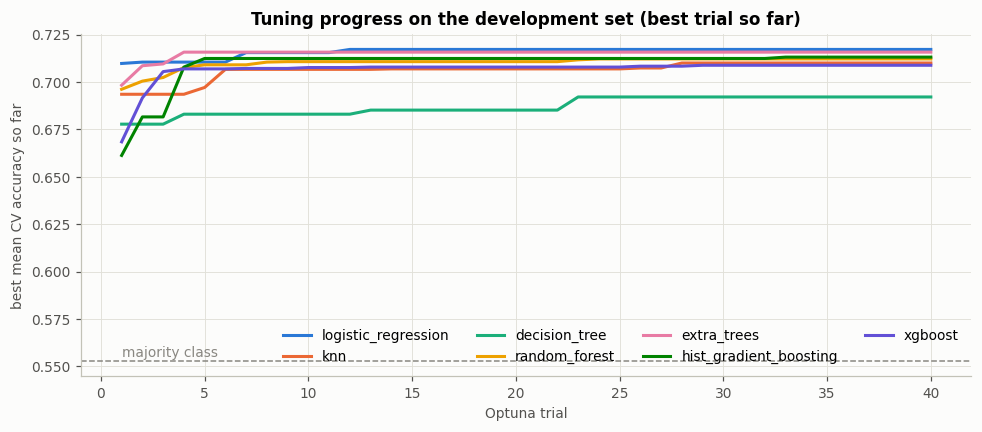

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
for name, t in tuned.items():
    values = pd.Series([tr.value for tr in t["study"].trials]).cummax()
    ax.plot(np.arange(1, len(values) + 1), values, color=MODEL_COLORS[name], label=name)
ax.axhline(baseline_table.loc["dummy (majority class)", METRIC], color=GREY, ls="--", lw=1)
ax.text(1, baseline_table.loc["dummy (majority class)", METRIC] + 0.002, "majority class", color=GREY)
ax.set(xlabel="Optuna trial", ylabel=f"best mean CV {METRIC} so far",
       title="Tuning progress on the development set (best trial so far)")
ax.legend(ncol=4, loc="lower right")
plt.tight_layout()
plt.show()

**What tuning changed:**

- **It helped most where the defaults overfit:** decision tree +0.030, histogram gradient boosting +0.025 and XGBoost +0.012 accuracy (nested vs untuned). Logistic regression gains +0.005. Random forest and extra trees end slightly *below* their untuned scores (−0.004 / −0.001): their defaults were already good, and tuning on a noisy metric with small inner folds adds variance.
- **Every search moved towards more regularisation:** a depth-3 tree, a depth-5 forest, an HGB with 5 leaves per tree, an XGBoost with 109 shallow trees at learning rate 0.026, k-NN with **k = 282** neighbours, and a logistic regression with a strong penalty (**C = 0.024**) and `class_weight="balanced"`. The signal is smooth and close to linear in the features, so flexible models gain little.
- **Optimism:** the best trial on the whole development set scores 0.3–1.1 points above the honest nested score, the usual winner's-curse from picking the best of 40 noisy trials. That is why models are compared on the nested scores. The negative `inner − outer` column is not an error: inside the outer folds the inner folds train on much less data (the earliest one on only 45 rows), so their scores are lower than the outer score of a model refitted on the whole outer-training block.

# <font color='#2E86C1' size=6>**5. Comparing evaluation metrics**</font> <a class="anchor" id="comparison"></a>

Every tuned model is compared on its **nested-CV** scores (honest), together with the three baselines, on all metrics:

- **accuracy** (selection metric, and the Kaggle metric) and **balanced accuracy** (accuracy averaged over both classes; the classes are 55 / 45);
- **precision / recall / F1** of class 1 (*returns*), at the default 0.5 threshold;
- **ROC-AUC** and **average precision**: quality of the *ranking*, independent of any threshold; this is what matters when the business targets the *k* customers most at risk (section 7);
- **Brier score** and **log loss**: quality of the *probabilities* themselves (lower is better); they matter when a probability is turned into an expected value.


[Back to TOC](#toc)

In [11]:
nested_results = {name: t["nested"] for name, t in tuned.items()}
comparison = summary_table({**nested_results, **baseline_scores})
display(fmt(comparison))
best_by_metric = {m: (comparison[m].idxmin() if m in LOWER_IS_BETTER else comparison[m].idxmax()) for m in SCORING}
print("best on each metric:", best_by_metric)

best_nested = comparison.loc[MODELS, METRIC].idxmax()
paired = pd.concat({metric: paired_table(nested_results, best_nested, metric) for metric in [METRIC, "roc_auc", "brier"]},
                   axis=1)
print(f"Every tuned model vs the best one on nested {METRIC} ({best_nested}); positive = better than {best_nested}:")
fmt(paired)

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,brier,log_loss,accuracy_std,train_accuracy,overfit_gap
model,,,,,,,,,,,,
logistic_regression,0.7126,0.7137,0.7578,0.7077,0.7305,0.7751,0.8270,0.1932,0.5691,0.0190,0.6783,-0.0343
extra_trees,0.7112,0.7052,0.7307,0.7594,0.7435,0.7816,0.8308,0.1917,0.5600,0.0128,0.7809,0.0697
hist_gradient_boosting,0.7086,0.7047,0.7369,0.7431,0.7370,0.7790,0.8295,0.1928,0.5617,0.0145,0.7585,0.0500
random_forest,0.7047,0.6970,0.7187,0.7679,0.7417,0.7782,0.8274,0.1927,0.5623,0.0151,0.7928,0.0880
xgboost,0.7033,0.6962,0.7198,0.7669,0.7401,0.7757,0.8273,0.1959,0.5728,0.0139,0.7502,0.0469
knn,0.7007,0.6980,0.7338,0.7195,0.7261,0.7626,0.8028,0.1991,0.9495,0.0073,0.7511,0.0504
decision_tree,0.6811,0.6640,0.6875,0.7795,0.7292,0.7407,0.7654,0.2036,0.6061,0.0215,0.6953,0.0142
recency rule,0.6677,0.6627,0.6998,0.6939,0.6967,0.6627,0.6548,0.2211,0.6340,0.0212,0.6585,-0.0092
RFM logistic regression,0.6634,0.6447,0.6553,0.8280,0.7308,0.7557,0.8106,0.2162,0.6401,0.0366,0.6455,-0.0179


best on each metric: {'accuracy': 'logistic_regression', 'balanced_accuracy': 'logistic_regression', 'precision': 'logistic_regression', 'recall': 'dummy (majority class)', 'f1': 'extra_trees', 'roc_auc': 'extra_trees', 'average_precision': 'extra_trees', 'brier': 'extra_trees', 'log_loss': 'extra_trees'}
Every tuned model vs the best one on nested accuracy (logistic_regression); positive = better than logistic_regression:


accuracy                                                roc_auc                                                  brier                         \
                       mean_advantage      se folds_a_better n_folds decisive mean_advantage      se folds_a_better n_folds decisive mean_advantage      se folds_a_better   
model                                                                                                                                                                        
extra_trees                   -0.0014  0.0068              3       5    False         0.0065  0.0032              4       5     True         0.0015  0.0027              4   
hist_gradient_boosting        -0.0041  0.0041              2       5    False         0.0039  0.0040              3       5    False         0.0004  0.0014              2   
random_forest                 -0.0079  0.0071              3       5    False         0.0031  0.0051              3       5    False         0.0005  0.0031              3   
xgboost                       -0.0093  0.0084              2       5    False         0.0006  0.0029              2       5    False        -0.0027  0.0029              1   
knn                           -0.0119  0.0063              2       5    False        -0.0125  0.0059              1       5     True        -0.0058  0.0044              1   
decision_tree                 -0.0315  0.0126              0       5     True        -0.0343  0.0113              0       5     True        -0.0104  0.0048              0   

                                         
                       n_folds decisive  
model                                    
extra_trees                  5    False  
hist_gradient_boosting       5    False  
random_forest                5    False  
xgboost                      5    False  
knn                          5    False  
decision_tree                5     True

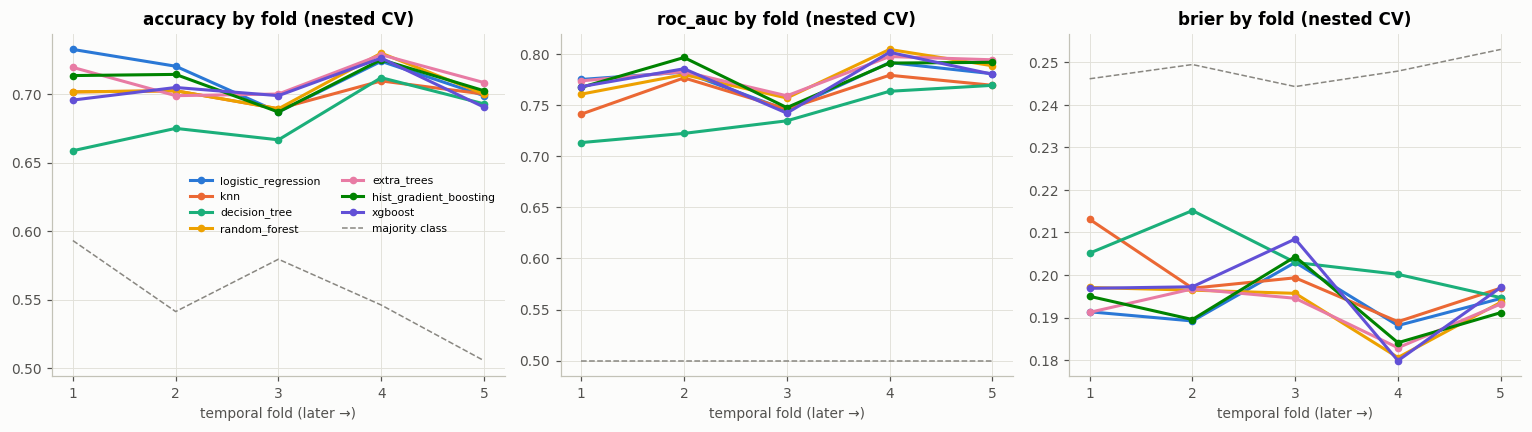

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric in zip(axes, [METRIC, "roc_auc", "brier"]):
    for name in MODELS:
        values = nested_results[name][f"validation_{metric}"].to_numpy()
        ax.plot(np.arange(1, len(values) + 1), values, marker="o", ms=4, color=MODEL_COLORS[name], label=name)
    dummy = baseline_scores["dummy (majority class)"][f"validation_{metric}"].to_numpy()
    ax.plot(np.arange(1, len(dummy) + 1), dummy, ls="--", color=GREY, lw=1, label="majority class")
    ax.set(xlabel="temporal fold (later →)", title=f"{metric} by fold (nested CV)", xticks=range(1, len(dummy) + 1))
axes[0].legend(ncol=2, fontsize=7)
plt.tight_layout()
plt.show()

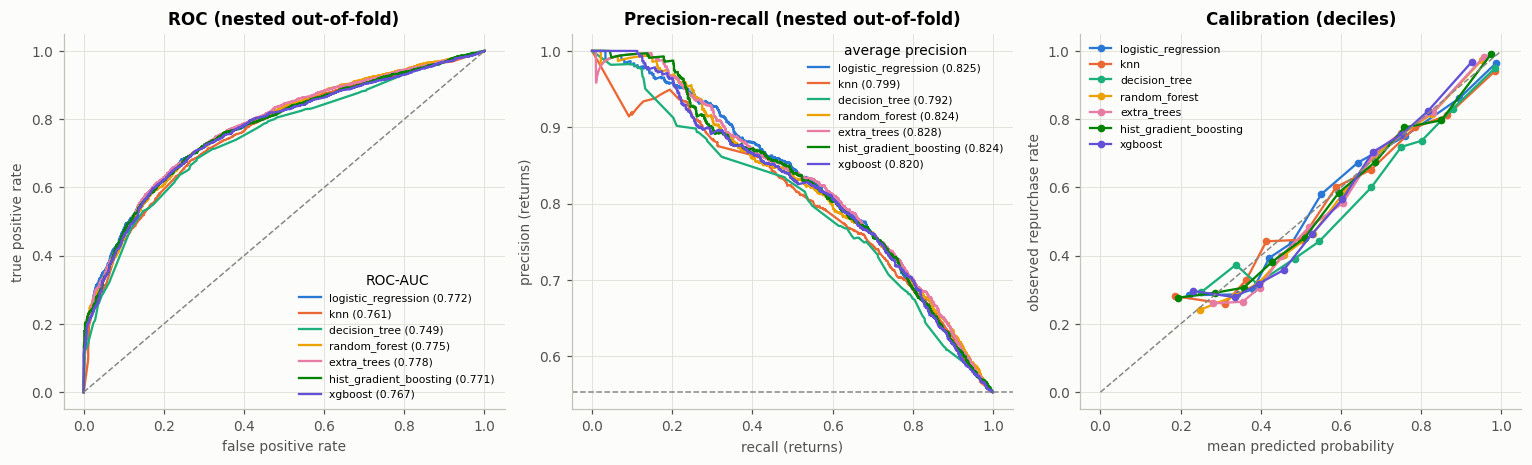

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
for name in MODELS:
    oof = tuned[name]["nested_oof"]
    seen = oof.notna().to_numpy()
    y_seen, p_seen = y_dev[seen], oof[seen]
    fpr, tpr, _ = roc_curve(y_seen, p_seen)
    axes[0].plot(fpr, tpr, color=MODEL_COLORS[name], lw=1.5, label=f"{name} ({roc_auc_score(y_seen, p_seen):.3f})")
    precision, recall, _ = precision_recall_curve(y_seen, p_seen)
    axes[1].plot(recall, precision, color=MODEL_COLORS[name], lw=1.5,
                 label=f"{name} ({average_precision_score(y_seen, p_seen):.3f})")
    observed, predicted = calibration_curve(y_seen, p_seen, n_bins=10, strategy="quantile")
    axes[2].plot(predicted, observed, marker="o", ms=4, color=MODEL_COLORS[name], lw=1.5, label=name)
axes[0].plot([0, 1], [0, 1], color=GREY, ls="--", lw=1)
axes[1].axhline(y_dev[seen].mean(), color=GREY, ls="--", lw=1)
axes[2].plot([0, 1], [0, 1], color=GREY, ls="--", lw=1)
axes[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC (nested out-of-fold)")
axes[1].set(xlabel="recall (returns)", ylabel="precision (returns)", title="Precision-recall (nested out-of-fold)")
axes[2].set(xlabel="mean predicted probability", ylabel="observed repurchase rate", title="Calibration (deciles)")
axes[0].legend(fontsize=7, title="ROC-AUC")
axes[1].legend(fontsize=7, title="average precision")
axes[2].legend(fontsize=7)
plt.tight_layout()
plt.show()

**Comparing the metrics (nested CV, honest):**

| | Best model | Value | Runner-up |
|---|---|---|---|
| accuracy | logistic regression | 0.713 | extra trees 0.711 (−0.001, tie) |
| balanced accuracy / precision | logistic regression | 0.714 / 0.758 | extra trees 0.705 / HGB 0.737 |
| recall / F1 | extra trees (F1) | 0.744 | forest 0.742 |
| ROC-AUC / average precision | extra trees | 0.782 / 0.831 | HGB 0.779 / 0.830 |
| Brier / log loss | extra trees | 0.192 / 0.560 | HGB 0.193 / 0.562 |

- **Six of the seven tuned models are statistically tied on accuracy.** Every difference to logistic regression is within 2 SE. The exception is the decision tree, which is decisively worse on accuracy, ROC-AUC and Brier.
- **Extra trees rank and calibrate slightly better.** Their ROC-AUC lead over logistic regression (+0.0065, SE 0.0032, 4/5 folds) is decisive, but it amounts to well under one point. Logistic regression is more *precise* at 0.5 (0.758 vs 0.731), extra trees more *sensitive* (recall 0.759 vs 0.708). They simply sit at different points of nearly the same ROC curve.
- **The folds vary more than the models do.** Accuracy moves from 0.69 to 0.73 between folds, but by about 0.01 between the top six models in any one fold. The time period matters more than the model family, which points to the features and to drift (section 6), not to the algorithm.
- **Calibration:** all models track the diagonal reasonably well. k-NN's log loss (0.95) is poor because some of its probabilities are exactly 0 or 1. All models are slightly too pessimistic in their lowest-probability decile (they predict about 0.2, observed about 0.28) and close to the diagonal above 0.5.
- **Against the baselines:** the best models add **+0.045 accuracy and +0.025 ROC-AUC over the best baseline** (recency rule / RFM model), and +0.16 accuracy over the floor.

# <font color='#2E86C1' size=6>**6. Final model and the locked test set**</font> <a class="anchor" id="final"></a>

**Selection rule** (the rule of notebook 01, section 7, applied to the nested-CV scores):

1. rank the tuned models by nested-CV accuracy;
2. if the top model is the current one (`config.yaml` → `classification.model`), keep it;
3. otherwise switch only if the top model is **decisively** better than the current one (more than 2 SE, fold by fold); if not, the current model stays.

The chosen model keeps the hyperparameters of its tuning on the whole development set, is refitted on all development rows, and is evaluated **once** on the locked test set. The majority-class floor is scored on the same rows for reference (it involves no choice).


[Back to TOC](#toc)

In [14]:
top_model = best_nested
vs_current = paired_comparison(nested_results[top_model][f"validation_{METRIC}"],
                               nested_results[CURRENT_MODEL][f"validation_{METRIC}"])
FINAL = top_model if (top_model == CURRENT_MODEL or vs_current["decisive"]) else CURRENT_MODEL
print(f"top model on nested {METRIC}: {top_model}")
print(f"{top_model} vs current model ({CURRENT_MODEL}): {vs_current}")
print(f"\n==> FINAL MODEL: {FINAL}")
print("hyperparameters:", {k.replace("model__", ""): v for k, v in tuned[FINAL]["study"].best_params.items()})

final_pipeline = clone(tuned[FINAL]["best"]).fit(X_dev, y_dev)
final_model = final_pipeline.named_steps["model"]
p_test = final_pipeline.predict_proba(X_test)[:, 1]
oof_final = tuned[FINAL]["nested_oof"]
seen = oof_final.notna().to_numpy()

top model on nested accuracy: logistic_regression
logistic_regression vs current model (logistic_regression): {'mean_advantage': np.float64(0.0), 'se': np.float64(0.0), 'folds_a_better': 0, 'n_folds': 5, 'decisive': False}

==> FINAL MODEL: logistic_regression
hyperparameters: {'C': 0.02448821505101427, 'class_weight': 'balanced'}


In [15]:
def score_all(y, p, threshold=0.5):
    pred = (p >= threshold).astype(int)
    return {"accuracy": accuracy_score(y, pred), "balanced_accuracy": balanced_accuracy_score(y, pred),
            "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred),
            "f1": f1_score(y, pred), "roc_auc": roc_auc_score(y, p), "average_precision": average_precision_score(y, p),
            "brier": brier_score_loss(y, p), "log_loss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6))}


dummy_test = clone(BASELINES["dummy (majority class)"]).fit(X_dev, y_dev).predict_proba(X_test)[:, 1]
rule_test = clone(BASELINES["recency rule"]).fit(X_dev, y_dev).predict_proba(X_test)[:, 1]
locked = pd.DataFrame({
    f"{FINAL}: nested CV (development)": nested_results[FINAL][[f"validation_{m}" for m in SCORING]].mean().set_axis(list(SCORING)),
    f"{FINAL}: locked test": score_all(y_test, p_test),
    "recency rule: locked test": score_all(y_test, rule_test),
    "majority class: locked test": score_all(y_test, dummy_test),
}).T
display(fmt(locked))
print(holdout_report(y_test, p_test))

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,brier,log_loss
logistic_regression: nested CV (development),0.7126,0.7137,0.7578,0.7077,0.7305,0.7751,0.8270,0.1932,0.5691
logistic_regression: locked test,0.7037,0.7159,0.8160,0.6572,0.7281,0.7838,0.8543,0.1917,0.5646
recency rule: locked test,0.6804,0.6666,0.7361,0.7332,0.7347,0.6666,0.7007,0.2139,0.6186
majority class: locked test,0.6034,0.5000,0.6034,1.0000,0.7527,0.5000,0.6034,0.2422,0.6775


Locked test set, evaluated once (1286 rows, threshold 0.5):
  accuracy: 0.7037   roc_auc: 0.7838   repurchase rate: true 0.603 / predicted 0.486

                        predicted 0  predicted 1
true 0 (no repurchase)          395          115
true 1 (repurchase)             266          510

              precision    recall  f1-score   support

           0       0.60      0.77      0.67       510
           1       0.82      0.66      0.73       776

    accuracy                           0.70      1286
   macro avg       0.71      0.72      0.70      1286
weighted avg       0.73      0.70      0.71      1286



**Final model: tuned logistic regression** (`C = 0.024`, `class_weight="balanced"`, full recipe). It has the highest nested-CV accuracy, so the selection rule doesn't even need its "keep the current model on a tie" clause. It is also the simplest, best-understood and cheapest model in the comparison, and its coefficients and SHAP values are exact.

The runner-up is extra trees (decisively better ROC-AUC by +0.0065, accuracy tied). It is the alternative if the main use becomes *ranking* customers for a limited budget rather than classifying them. On the selection metric, the gain is too small to justify a 187-tree ensemble.

**Locked test set (scored once):**

- **accuracy 0.704, ROC-AUC 0.784**, against nested-CV estimates of 0.713 / 0.775. Accuracy is within one fold standard deviation of the estimate, and ROC-AUC is even slightly higher, so the CV estimate was honest.
- It beats the majority class (0.603) by **+0.100** and the recency rule (0.680) by **+0.023**. Its ranking is far better than the rule's (ROC-AUC 0.784 vs 0.667).
- **Base-rate drift:** 60.3 % of locked-test purchases are followed by another purchase, against 55.0 % in development. The model predicts only 48.6 % returners at 0.5, so it is cautious: recall 0.66 for returners, precision 0.82. Part of this comes from `class_weight="balanced"`, which centres the probabilities on a 50 / 50 split. The ranking is unaffected; the threshold is what drift moves (section 7).

# <font color='#2E86C1' size=6>**7. Classification threshold and business implications**</font> <a class="anchor" id="threshold"></a>

The model outputs a **probability of return**; a threshold turns it into a decision. 0.5 maximises accuracy only if the probabilities are calibrated and both errors cost the same. In this business they don't:

- the action is a **retention incentive** (voucher / call) for customers predicted **not** to return;
- a **missed churner** (predicted to return, doesn't) loses the margin the incentive might have saved;
- a **wasted incentive** (targeted, would have returned anyway) costs the incentive.

**All thresholds are chosen on the development set** (nested out-of-fold probabilities of the final model: each one comes from a model that never saw that row or tuned on it). The locked test set only *confirms* them.

### 7.1 Metrics across thresholds


[Back to TOC](#toc)

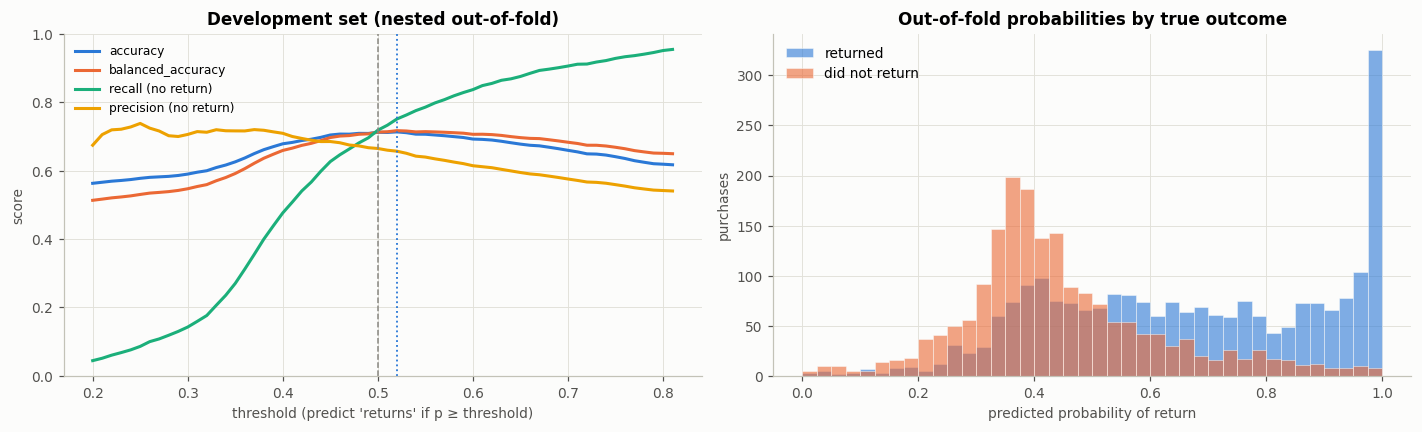

accuracy-optimal threshold (dev): 0.52   balanced-accuracy-optimal: 0.52


,accuracy,balanced_accuracy,precision (returns),recall (returns),precision (no return),recall (no return),f1 (returns),share predicted to return
threshold,,,,,,,,
0.40,0.6789,0.6595,0.6658,0.8423,0.7096,0.4768,0.7437,0.6997
0.45,0.7047,0.6973,0.7180,0.7676,0.6856,0.6269,0.7420,0.5913
0.50,0.7126,0.7132,0.7569,0.7076,0.6652,0.7189,0.7314,0.5170
0.52,0.7138,0.7174,0.7728,0.6834,0.6573,0.7515,0.7254,0.4890
0.55,0.7069,0.7145,0.7881,0.6428,0.6401,0.7862,0.7081,0.4510
0.60,0.6928,0.7067,0.8143,0.5758,0.6148,0.8375,0.6746,0.3911


Locked test set at those thresholds (confirmation only):


,accuracy,balanced_accuracy,precision,recall,f1
threshold 0.50,0.7037,0.7159,0.8160,0.6572,0.7281
threshold 0.52,0.6960,0.7148,0.8302,0.6237,0.7123


In [16]:
def threshold_table(y, p, thresholds):
    rows = []
    for t in thresholds:
        pred = (p >= t).astype(int)
        rows.append({"threshold": t, "accuracy": accuracy_score(y, pred),
                     "balanced_accuracy": balanced_accuracy_score(y, pred),
                     "precision (returns)": precision_score(y, pred, zero_division=0),
                     "recall (returns)": recall_score(y, pred, zero_division=0),
                     "precision (no return)": precision_score(y, pred, pos_label=0, zero_division=0),
                     "recall (no return)": recall_score(y, pred, pos_label=0, zero_division=0),
                     "f1 (returns)": f1_score(y, pred, zero_division=0),
                     "share predicted to return": pred.mean()})
    return pd.DataFrame(rows).set_index("threshold")


THRESHOLDS = np.round(np.arange(0.20, 0.81, 0.01), 2)
y_oof, p_oof = y_dev[seen].to_numpy(), oof_final[seen].to_numpy()
dev_thresholds = threshold_table(y_oof, p_oof, THRESHOLDS)
t_accuracy = float(dev_thresholds["accuracy"].idxmax())
t_balanced = float(dev_thresholds["balanced_accuracy"].idxmax())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for column, color in zip(["accuracy", "balanced_accuracy", "recall (no return)", "precision (no return)"], PALETTE):
    axes[0].plot(dev_thresholds.index, dev_thresholds[column], color=color, label=column)
axes[0].axvline(0.5, color=GREY, ls="--", lw=1)
axes[0].axvline(t_accuracy, color=PALETTE[0], ls=":", lw=1.2)
axes[0].set(xlabel="threshold (predict 'returns' if p ≥ threshold)", ylabel="score",
            title="Development set (nested out-of-fold)")
axes[0].legend(fontsize=8)
for label, cls, color in [("returned", 1, PALETTE[0]), ("did not return", 0, PALETTE[1])]:
    axes[1].hist(p_oof[y_oof == cls], bins=40, range=(0, 1), alpha=0.6, color=color, label=label,
                 edgecolor="#fcfcfb", linewidth=0.5)
axes[1].set(xlabel="predicted probability of return", ylabel="purchases", title="Out-of-fold probabilities by true outcome")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"accuracy-optimal threshold (dev): {t_accuracy:.2f}   balanced-accuracy-optimal: {t_balanced:.2f}")
display(fmt(dev_thresholds.loc[sorted({0.4, 0.45, 0.5, 0.55, 0.6, t_accuracy, t_balanced})]))

check = pd.DataFrame({f"threshold {t:.2f}": score_all(y_test, p_test, t) for t in sorted({0.5, t_accuracy, t_balanced})}).T
print("Locked test set at those thresholds (confirmation only):")
fmt(check[["accuracy", "balanced_accuracy", "precision", "recall", "f1"]])

### 7.2 A value model for the retention campaign

**Assumptions** (business inputs; the defaults below come from the data where possible and are varied in 7.4):

| Input | Default | Source |
|---|---|---|
| value of a returning customer, `V` | mean 90-day spend of returners × gross margin rate | development set: `spend_next_90d` of repeat purchasers (regression rows) × `(net_total − cost) / net_total` |
| incentive cost per targeted customer, `C` | €50 | assumption (voucher + contact) |
| uplift `u`: share of would-be non-returners won back by the incentive | 10 % | assumption (typical retention-campaign response) |

For a campaign that targets the customers with `p < t` (predicted *not* to return), relative to doing nothing:

$$\text{profit}(t) = u \cdot V \cdot \#\{\text{targeted non-returners}\} \;-\; C \cdot \#\{\text{targeted}\}$$

Customers who would have returned anyway bring no extra value but still cost `C`. With calibrated probabilities, a customer is worth targeting when `(1 − p) · u · V > C`, i.e. when **`p < 1 − C / (u·V)`**: the theoretical break-even threshold.

mean 90-day spend of a returner: €1,836 x gross margin 57.6% = value V = €1,057
incentive cost C = €50, uplift u = 10%  ->  break-even: target if p < 0.527


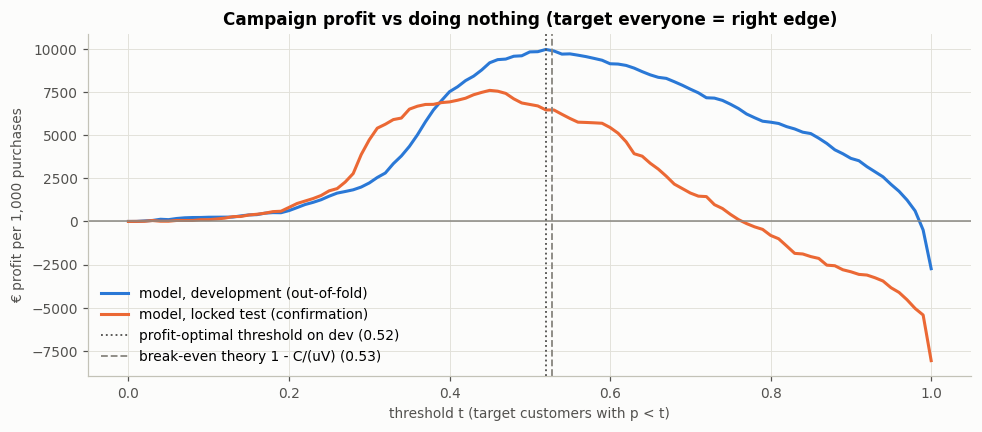

In [17]:
regression_rows = prepare_task_data(config, "regression")
SPEND_90D = float(regression_rows["y_dev"].mean())
net, cost = X_dev["net_total"].astype(float), X_dev["cost"].astype(float)
MARGIN_RATE = float((net - cost).sum() / net.sum())
VALUE = SPEND_90D * MARGIN_RATE
INCENTIVE_COST, UPLIFT = 50.0, 0.10
t_theory = 1 - INCENTIVE_COST / (UPLIFT * VALUE)
print(f"mean 90-day spend of a returner: €{SPEND_90D:,.0f} x gross margin {MARGIN_RATE:.1%} = value V = €{VALUE:,.0f}")
print(f"incentive cost C = €{INCENTIVE_COST:.0f}, uplift u = {UPLIFT:.0%}  ->  break-even: target if p < {t_theory:.3f}")


def campaign(y, p, t, value=VALUE, cost=INCENTIVE_COST, uplift=UPLIFT):
    '''Profit per 1,000 purchases of targeting p < t, and what the campaign does.'''
    y, p = np.asarray(y), np.asarray(p)
    target = p < t
    won_back = uplift * ((y == 0) & target).sum()
    profit = value * won_back - cost * target.sum()
    return {"profit per 1,000": 1000 * profit / len(y), "share targeted": target.mean(),
            "non-returners reached": ((y == 0) & target).sum() / max((y == 0).sum(), 1),
            "wasted incentives (returners targeted)": ((y == 1) & target).sum() / max(target.sum(), 1)}


def campaign_curve(y, p, thresholds, **kw):
    return pd.DataFrame({t: campaign(y, p, t, **kw) for t in thresholds}).T


CURVE_T = np.round(np.arange(0.0, 1.001, 0.01), 2)
dev_campaign = campaign_curve(y_oof, p_oof, CURVE_T)
t_profit = float(dev_campaign["profit per 1,000"].idxmax())

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(dev_campaign.index, dev_campaign["profit per 1,000"], color=PALETTE[0], label="model, development (out-of-fold)")
ax.plot(CURVE_T, campaign_curve(y_test, p_test, CURVE_T)["profit per 1,000"], color=PALETTE[1],
        label="model, locked test (confirmation)")
ax.axhline(0, color=GREY, lw=1)
ax.axvline(t_profit, color=INK, ls=":", lw=1.2, label=f"profit-optimal threshold on dev ({t_profit:.2f})")
ax.axvline(t_theory, color=GREY, ls="--", lw=1.2, label=f"break-even theory 1 - C/(uV) ({t_theory:.2f})")
ax.set(xlabel="threshold t (target customers with p < t)", ylabel="€ profit per 1,000 purchases",
       title="Campaign profit vs doing nothing (target everyone = right edge)")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

In [18]:
strategies = {
    "nobody (no campaign)": np.full(len(y_test), 1.0),
    "everyone": np.zeros(len(y_test)),
    "recency rule (no purchase in last 90 days)": rule_test,
}
rows = {}
for name, scores in strategies.items():
    rows[name] = campaign(y_test, scores, 0.5)
rows["model, threshold 0.50"] = campaign(y_test, p_test, 0.5)
rows[f"model, accuracy-optimal threshold {t_accuracy:.2f}"] = campaign(y_test, p_test, t_accuracy)
rows[f"model, profit-optimal threshold {t_profit:.2f} (chosen on dev)"] = campaign(y_test, p_test, t_profit)
rows["perfect foresight (target exactly the non-returners)"] = campaign(y_test, 1 - (y_test.to_numpy() == 0), 0.5)
business = pd.DataFrame(rows).T
business["profit per 1,000"] = business["profit per 1,000"].round(0)
print("Locked test set, value per 1,000 purchases relative to no campaign:")
fmt(business, 3)

Locked test set, value per 1,000 purchases relative to no campaign:


,"profit per 1,000",share targeted,non-returners reached,wasted incentives (returners targeted)
nobody (no campaign),0.0,0.000,0.000,0.000
everyone,-8065.0,1.000,1.000,0.603
recency rule (no purchase in last 90 days),5215.0,0.399,0.600,0.404
"model, threshold 0.50",6779.0,0.514,0.775,0.402
"model, accuracy-optimal threshold 0.52",6462.0,0.547,0.806,0.415
"model, profit-optimal threshold 0.52 (chosen on dev)",6462.0,0.547,0.806,0.415
perfect foresight (target exactly the non-returners),22106.0,0.397,1.000,0.000


### 7.3 Who to call first: gains chart

When the budget only covers part of the customers, the question is not *which threshold* but *how many of the real non-returners are in the first k % of the list*, ordered from the lowest probability of return. That depends only on the ranking (ROC-AUC), not on calibration.

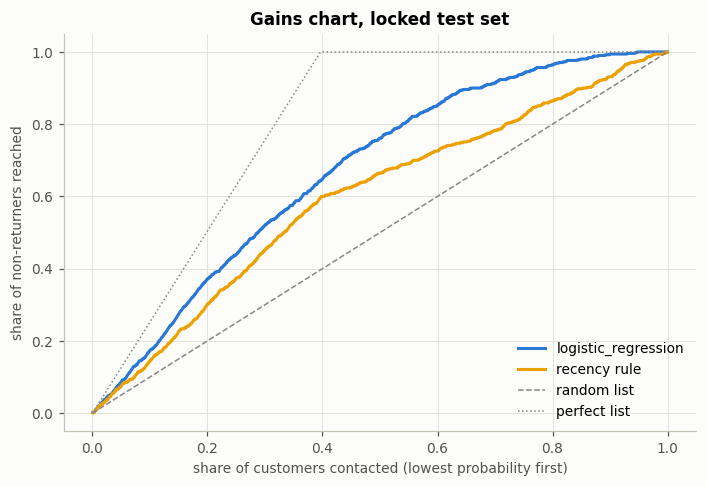

,non-returners reached,lift vs random,non-returner rate in the list
contacted,,,
10%,0.175,1.745,0.690
20%,0.373,1.863,0.736
30%,0.522,1.739,0.689
40%,0.649,1.623,0.643
50%,0.761,1.522,0.603


In [19]:
def gains(y, p):
    order = np.argsort(p, kind="stable")                    # lowest probability of return first
    churn = (np.asarray(y)[order] == 0).astype(int)
    return np.arange(1, len(churn) + 1) / len(churn), np.cumsum(churn) / churn.sum()


share, captured = gains(y_test, p_test)
share_rule, captured_rule = gains(y_test, rule_test + np.random.default_rng(SEED).uniform(0, 1e-6, len(rule_test)))
base_churn = (y_test == 0).mean()
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(share, captured, color=PALETTE[0], label=f"{FINAL}")
ax.plot(share_rule, captured_rule, color=PALETTE[3], label="recency rule")
ax.plot([0, 1], [0, 1], color=GREY, ls="--", lw=1, label="random list")
ax.plot([0, base_churn, 1], [0, 1, 1], color=GREY, ls=":", lw=1, label="perfect list")
ax.set(xlabel="share of customers contacted (lowest probability first)", ylabel="share of non-returners reached",
       title="Gains chart, locked test set")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

gain_rows = []
for k in [0.1, 0.2, 0.3, 0.4, 0.5]:
    i = int(np.ceil(k * len(share))) - 1
    gain_rows.append({"contacted": f"{k:.0%}", "non-returners reached": captured[i],
                      "lift vs random": captured[i] / k,
                      "non-returner rate in the list": captured[i] * (y_test == 0).sum() / (i + 1)})
fmt(pd.DataFrame(gain_rows).set_index("contacted"), 3)

### 7.4 How sensitive is the decision to the business assumptions?

The incentive cost and the uplift are assumptions. For each pair: the profit-optimal threshold **chosen on the development set**, and the profit it earns on the locked test set compared with the best *simple* strategy (contact everyone or nobody).

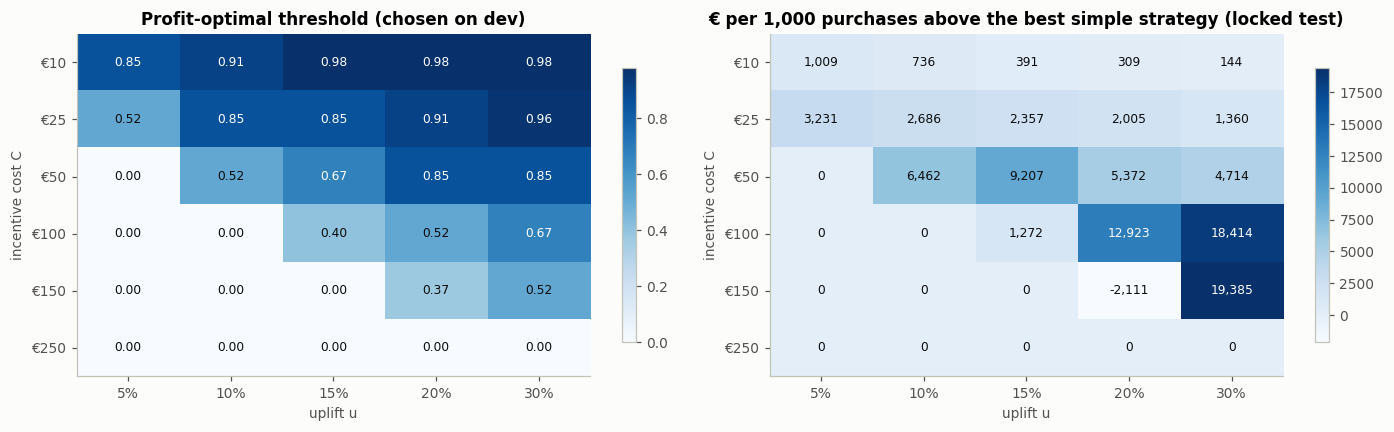

In [20]:
COSTS, UPLIFTS = [10, 25, 50, 100, 150, 250], [0.05, 0.10, 0.15, 0.20, 0.30]
opt_threshold, gain_vs_simple = pd.DataFrame(index=COSTS, columns=UPLIFTS, dtype=float), pd.DataFrame(index=COSTS, columns=UPLIFTS, dtype=float)
for c in COSTS:
    for u in UPLIFTS:
        t_best = float(campaign_curve(y_oof, p_oof, CURVE_T, cost=c, uplift=u)["profit per 1,000"].idxmax())
        model_profit = campaign(y_test, p_test, t_best, cost=c, uplift=u)["profit per 1,000"]
        simple = max(0.0, campaign(y_test, np.zeros(len(y_test)), 0.5, cost=c, uplift=u)["profit per 1,000"])
        opt_threshold.loc[c, u], gain_vs_simple.loc[c, u] = t_best, model_profit - simple
opt_threshold.index.name = gain_vs_simple.index.name = "incentive cost C (€)"
opt_threshold.columns.name = gain_vs_simple.columns.name = "uplift u"

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, table, title, fmt_ in [(axes[0], opt_threshold, "Profit-optimal threshold (chosen on dev)", "{:.2f}"),
                               (axes[1], gain_vs_simple, "€ per 1,000 purchases above the best simple strategy (locked test)", "{:,.0f}")]:
    image = ax.imshow(table.to_numpy(dtype=float), cmap="Blues", aspect="auto")
    ax.set_xticks(range(len(UPLIFTS)), [f"{u:.0%}" for u in UPLIFTS])
    ax.set_yticks(range(len(COSTS)), [f"€{c}" for c in COSTS])
    ax.set(xlabel="uplift u", ylabel="incentive cost C", title=title)
    ax.grid(False)
    values = table.to_numpy(dtype=float)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            dark = values[i, j] > np.nanmin(values) + 0.6 * (np.nanmax(values) - np.nanmin(values))
            ax.text(j, i, fmt_.format(values[i, j]), ha="center", va="center", fontsize=8,
                    color="#ffffff" if dark else "#0b0b0b")
    fig.colorbar(image, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

**What the threshold analysis shows:**

1. **For accuracy, 0.5 is as good as any threshold.** On development, accuracy is flat between 0.45 and 0.55 (0.705–0.714). The optimum, 0.52, is 0.001 above 0.5, which is noise. On the locked test set, 0.5 is in fact better (0.704 vs 0.696) because of the higher return rate. **Keep 0.5 for the Kaggle (accuracy) submission.**
2. **For the retention campaign, the threshold is a business decision.** With `V` = €1,057 (mean 90-day spend €1,836 × margin 57.6 %), `C` = €50 and `u` = 10 %:
   - The theoretical break-even threshold `1 − C/(uV)` = **0.527** matches the profit-optimal threshold found on development (**0.52**). That match only happens when the probabilities are well calibrated.
   - On the locked test set, the campaign targets 55 % of purchases, reaches **81 % of the non-returners**, and earns **€6,462 per 1,000 purchases**. That beats the recency rule (€5,215) and is far better than contacting everyone (−€8,065, since most incentives would go to customers who return anyway). It captures about 30 % of the €22,106 that perfect foresight would earn.
   - **Drift moves the best threshold.** On the test period, profit peaks near 0.45 (about €7,600): with more returners, fewer customers needed the incentive. In production, the threshold should be re-checked on the latest labelled quarter, or the intercept re-calibrated to the current return rate.
3. **On a limited budget, use the ranking, not a threshold.** Contacting the **20 % lowest-probability customers reaches 37 % of the non-returners** (lift 1.9×), and 30 % reaches 52 %. About 70 % of the customers on such a list really don't return, against 40 % at random.
4. **The assumptions matter more than the model.** If `u·V` is not clearly above `C` (e.g. C ≥ €100 with u ≤ 10 %, or C = €250), the best decision is **no campaign** (threshold 0). If incentives are cheap (C ≤ €25), almost everyone should be contacted except the surest returners (threshold 0.85–0.98 in most cells). The model adds the most value in between (C €50–150, u 15–30 %: €1k–19k per 1,000 purchases above the best simple strategy). One cell (C = €150, u = 20 %) loses €2.1k: its threshold sits on the steep edge of the profit curve, where small calibration errors cost a lot.

**Recommendation:** before scaling the campaign, measure the real uplift `u` with a pilot that keeps a random control group, then set the threshold with `1 − C/(uV)` and re-check it on the latest quarter.

# <font color='#2E86C1' size=6>**8. Explainability: SHAP and LIME**</font> <a class="anchor" id="explainability"></a>

**SHAP** (SHapley Additive exPlanations) splits each prediction into one contribution per feature that sums, with the base value, to the model output. It is used **globally** (the distribution of contributions over many customers) and **locally** (one customer). **LIME** fits a small linear model around one customer on perturbed copies of that customer: a second, independent local explanation to check SHAP against.

**Units and readability.** The model sees standardised numbers; scaling is a per-column linear map, so a contribution is the same whether it is written against the scaled or the original value. The plots therefore show values in their **original units** (after imputation): days, counts, euros. A categorical column enters the model as its **target encoding**: the historical repurchase rate of that category (e.g. of that salesperson), so its "value" is a rate between 0 and 1.

The explained rows are the **locked test set** (purchases the model never saw), with the final model fitted on the development set.


[Back to TOC](#toc)

In [21]:
NUMERIC = list(recipe["numeric_features"])
BINARY = ["spend_365d_missing"] + list(recipe["flag_features"])


def clean_name(name):
    group, column = name.split("__", 1)
    return column.replace("missingindicator_", "") + "_missing" if group == "indicators" else column


def model_inputs(pipeline, X):
    '''(scaled model input, the same in original units), both with readable column names.'''
    prep = pipeline.named_steps["prep"]
    names = [clean_name(n) for n in prep.get_feature_names_out()]
    scaled = pd.DataFrame(prep.transform(X), columns=names, index=X.index)
    readable = scaled.copy()
    readable[NUMERIC] = prep.named_transformers_["numeric"].named_steps["impute"].transform(X[NUMERIC])
    return scaled, readable


def readable_to_model(pipeline, values, columns):
    '''Original units -> the scaled input the model was trained on (used by LIME).'''
    frame = pd.DataFrame(np.asarray(values, dtype=float), columns=columns)
    scaler = pipeline.named_steps["prep"].named_transformers_["numeric"].named_steps["scale"]
    if scaler != "passthrough":
        frame[NUMERIC] = scaler.transform(frame[NUMERIC].to_numpy())
    return frame.to_numpy()


def shap_explanation(name, pipeline, X, background):
    '''SHAP values of the probability-of-return model, with original-unit data for the plots.
    Linear model -> LinearExplainer (log-odds); trees -> TreeExplainer (log-odds for boosters,
    probability for forests / single trees); anything else -> permutation explainer (probability).'''
    scaled, readable = model_inputs(pipeline, X)
    model = pipeline.named_steps["model"]
    bg_scaled = model_inputs(pipeline, background)[0].to_numpy()
    if name == "logistic_regression":
        explainer = shap.LinearExplainer(model, bg_scaled)
        values, base, unit = explainer.shap_values(scaled.to_numpy()), explainer.expected_value, "log-odds"
    elif name in TREE_MODELS:
        explainer = shap.TreeExplainer(model)
        values, base = explainer.shap_values(scaled.to_numpy()), explainer.expected_value
        values = np.asarray(values[1] if isinstance(values, list) else values)
        values = values[:, :, 1] if values.ndim == 3 else values
        base = np.atleast_1d(base)
        base = base[1] if len(base) == 2 else base[0]
        unit = "log-odds" if name in {"xgboost", "hist_gradient_boosting"} else "probability"
    else:
        background_sample = shap.sample(bg_scaled, 100, random_state=SEED)
        explainer = shap.PermutationExplainer(lambda a: model.predict_proba(a)[:, 1], background_sample)
        result = explainer(scaled.to_numpy())
        values, base, unit = result.values, result.base_values, "probability"
    base = np.broadcast_to(np.asarray(base, dtype=float), (len(scaled),))
    return shap.Explanation(values=np.asarray(values, dtype=float), base_values=base, data=readable.to_numpy(),
                            feature_names=list(readable.columns)), unit, scaled, readable


final_expl, final_unit, Xs_test, Xr_test = shap_explanation(FINAL, final_pipeline, X_test, X_dev)
# additivity check: base value + contributions = the model's own output for every row
output = final_expl.base_values + final_expl.values.sum(axis=1)
direct = final_model.predict_proba(Xs_test.to_numpy())[:, 1]
direct = np.log(direct / (1 - direct)) if final_unit == "log-odds" else direct
print(f"final model: {FINAL}; SHAP unit: {final_unit}; base value {final_expl.base_values[0]:.3f}; "
      f"max |sum of SHAP - model output| = {np.abs(output - direct).max():.2e}")

Background dataset has 5024 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5024 when initializing the masker.


final model: logistic_regression; SHAP unit: log-odds; base value 0.505; max |sum of SHAP - model output| = 1.37e-12


### 8.1 Global explanation

**Beeswarm:** one dot per customer and feature; the horizontal position is the contribution to the predicted return (right = more likely to return), the colour is the feature's value (red = high). **Bar:** mean |SHAP|, the average size of each feature's contribution.

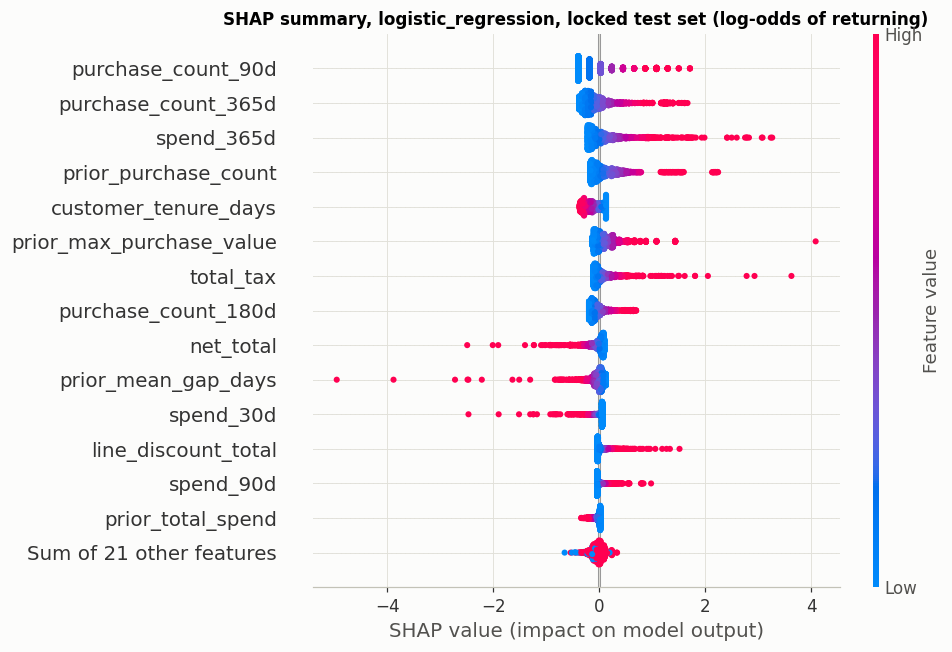

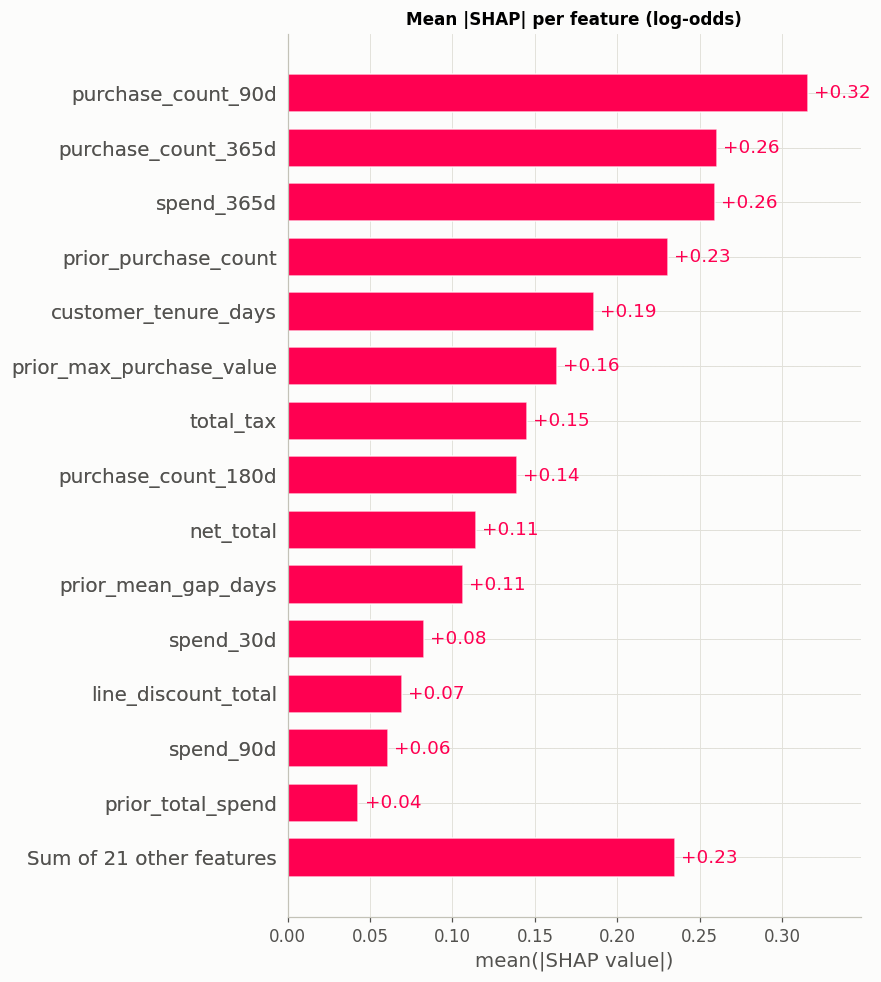

In [22]:
shap.plots.beeswarm(final_expl, max_display=15, show=False, plot_size=(9, 6))
plt.title(f"SHAP summary, {FINAL}, locked test set ({final_unit} of returning)")
plt.tight_layout()
plt.show()

shap.plots.bar(final_expl, max_display=15, show=False)
plt.title(f"Mean |SHAP| per feature ({final_unit})")
plt.tight_layout()
plt.show()

### 8.2 Local explanations: three customers

Three purchases from the locked test set: the one the model is **most confident will return**, the one **most at risk** (lowest probability), and a **borderline** case at the business threshold of section 7. For each: the SHAP waterfall (how the features move the prediction away from the base value), then LIME on the same customer, then how much the two agree.

In [23]:
cases = {
    "most likely to return": int(np.argmax(p_test)),
    "most at risk": int(np.argmin(p_test)),
    f"borderline (p ≈ {t_profit:.2f})": int(np.argmin(np.abs(p_test - t_profit))),
}
show_columns = ["days_since_previous_purchase", "prior_purchase_count", "purchase_count_90d", "purchase_count_365d",
                "prior_mean_gap_days", "customer_tenure_days", "prior_total_spend", "net_total"]
case_table = X_test.iloc[list(cases.values())][show_columns].copy()
case_table.insert(0, "case", list(cases))
case_table["p(return)"] = p_test[list(cases.values())]
case_table["actually returned"] = y_test.iloc[list(cases.values())].to_numpy()
case_table.set_index("case")

,days_since_previous_purchase,prior_purchase_count,purchase_count_90d,purchase_count_365d,prior_mean_gap_days,customer_tenure_days,prior_total_spend,net_total,p(return),actually returned
case,,,,,,,,,,
most likely to return,23.0,181,7,28,11.200000,2039,158127.93,436.52,0.999945,1
most at risk,70.0,2,1,1,3199.000000,3269,1968.80,416.44,0.003350,0
borderline (p ≈ 0.52),147.0,45,0,3,68.068182,3142,52183.30,1868.08,0.520001,0


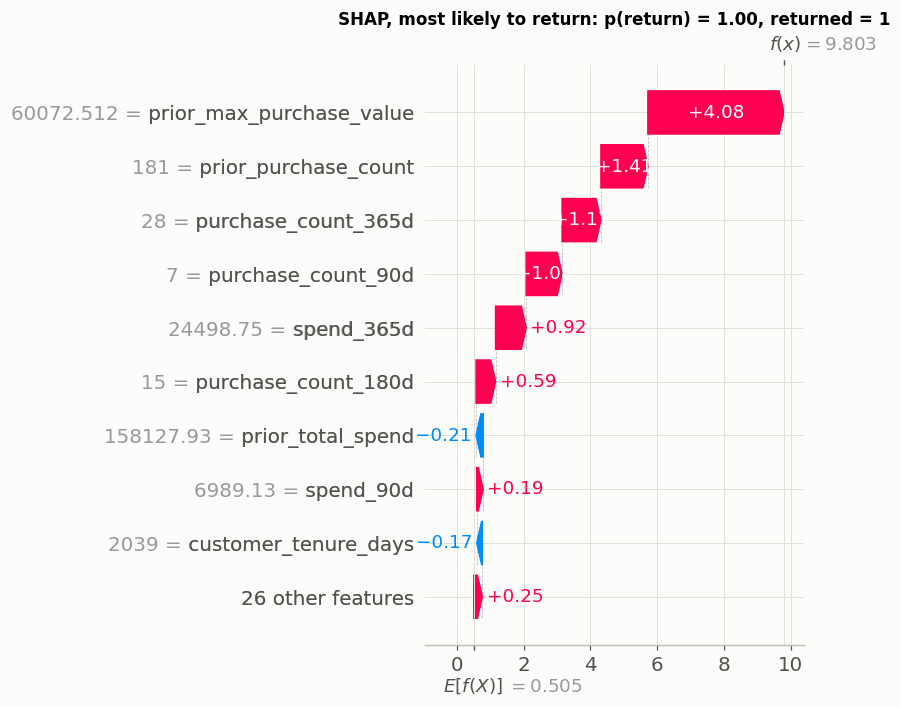

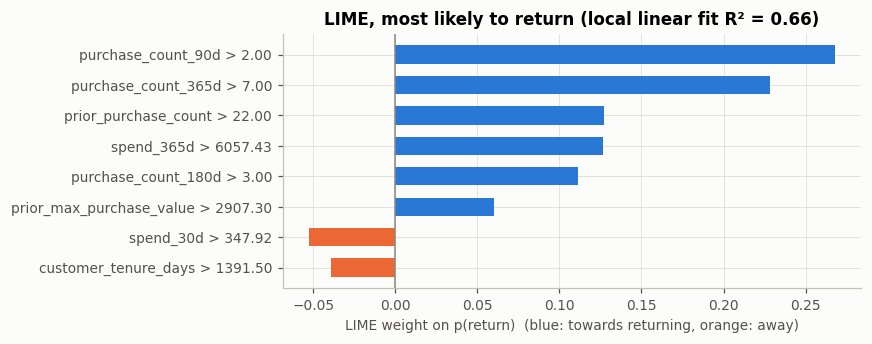

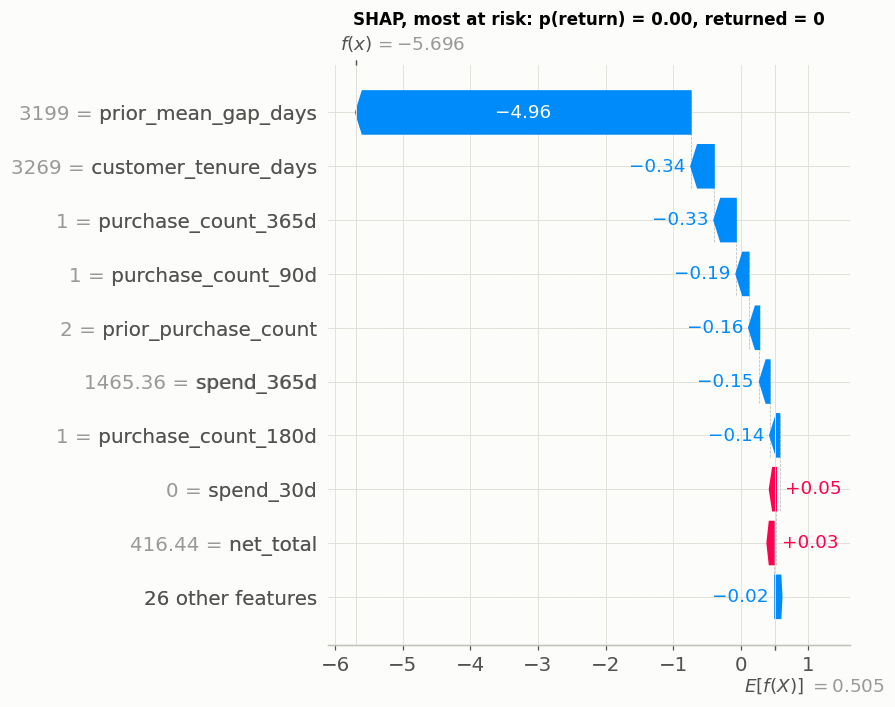

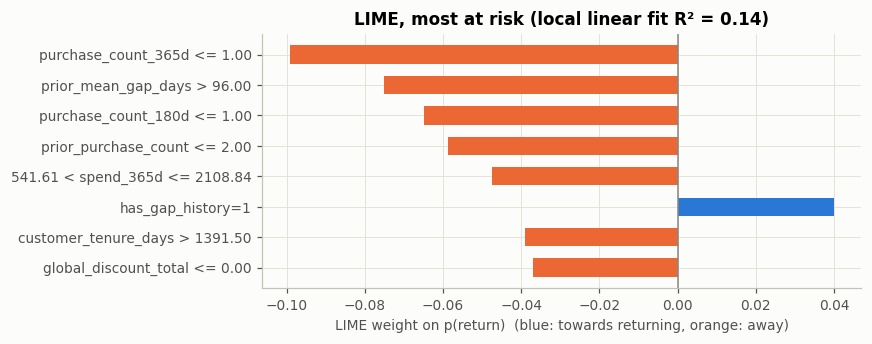

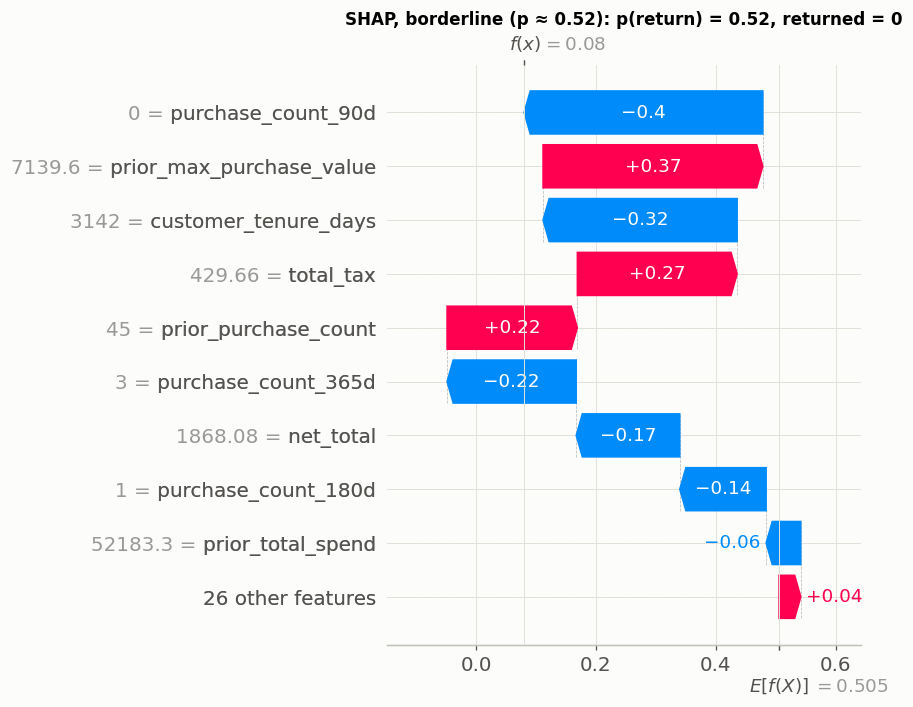

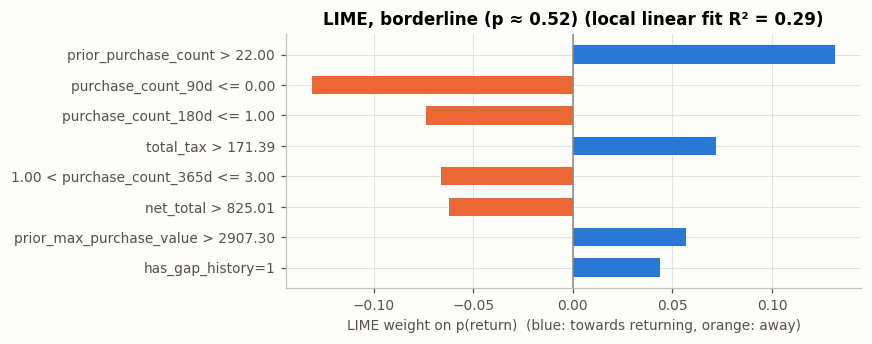

,shared features in the top 8,same direction (of shared),SHAP top 3,LIME top 3
case,,,,
most likely to return,6,6,"prior_max_purchase_value, prior_purchase_count, purchase_count_365d","purchase_count_90d, purchase_count_365d, prior_purchase_count"
most at risk,6,6,"prior_mean_gap_days, customer_tenure_days, purchase_count_365d","purchase_count_365d, prior_mean_gap_days, purchase_count_180d"
borderline (p ≈ 0.52),7,7,"purchase_count_90d, prior_max_purchase_value, customer_tenure_days","prior_purchase_count, purchase_count_90d, purchase_count_180d"


In [24]:
lime_explainer = LimeTabularExplainer(
    model_inputs(final_pipeline, X_dev)[1].to_numpy(), feature_names=list(Xr_test.columns),
    class_names=["no return", "return"], categorical_features=[list(Xr_test.columns).index(c) for c in BINARY],
    discretize_continuous=True, mode="classification", random_state=SEED)
predict_fn = lambda values: final_model.predict_proba(readable_to_model(final_pipeline, values, list(Xr_test.columns)))
TOP_K = 8
agreement = []
for label, i in cases.items():
    shap.plots.waterfall(final_expl[i], max_display=10, show=False)
    plt.title(f"SHAP, {label}: p(return) = {p_test[i]:.2f}, returned = {y_test.iloc[i]}")
    plt.tight_layout()
    plt.show()

    lime_exp = lime_explainer.explain_instance(Xr_test.iloc[i].to_numpy(), predict_fn, num_features=TOP_K,
                                               num_samples=5000, labels=(1,))
    weights = lime_exp.as_list(label=1)
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.barh([w[0] for w in weights][::-1], [w[1] for w in weights][::-1],
            color=[PALETTE[0] if w[1] > 0 else PALETTE[1] for w in weights][::-1], height=0.6)
    ax.axvline(0, color=GREY, lw=1)
    ax.set(xlabel="LIME weight on p(return)  (blue: towards returning, orange: away)",
           title=f"LIME, {label} (local linear fit R² = {lime_exp.score:.2f})")
    plt.tight_layout()
    plt.show()

    lime_weights = dict(lime_exp.as_map()[1])
    shap_values = final_expl.values[i]
    shap_top = set(np.argsort(-np.abs(shap_values))[:TOP_K])
    shared = shap_top & set(lime_weights)
    agreement.append({"case": label, f"shared features in the top {TOP_K}": len(shared),
                      "same direction (of shared)": sum(np.sign(shap_values[j]) == np.sign(lime_weights[j]) for j in shared),
                      "SHAP top 3": ", ".join(Xr_test.columns[j] for j in np.argsort(-np.abs(shap_values))[:3]),
                      "LIME top 3": ", ".join(Xr_test.columns[j] for j, _ in sorted(lime_weights.items(), key=lambda kv: -abs(kv[1]))[:3])})
pd.DataFrame(agreement).set_index("case")

**Global explanation:**

- The largest contributions come from **recent and overall purchase frequency** (`purchase_count_90d`, `purchase_count_365d`, `prior_purchase_count`, `purchase_count_180d`) and **monetary history** (`spend_365d`, `prior_max_purchase_value`). High values push towards returning.
- The main negative contributions are a **long usual gap between purchases** (`prior_mean_gap_days`), a **long tenure for the same number of purchases** (`customer_tenure_days`), a **large current invoice** (`net_total`) and a high 30-day spend (`spend_30d`). The last two, given the rest of the history, look like a stock-up purchase that delays the next one.
- The model is linear in log-odds, so each SHAP value is exactly `coefficient × (value − average)` and the additivity check is exact (error about 1e-12). The flip side is that **effects never saturate**. The observed rates in section 10 flatten at high values, but the model keeps extrapolating in a straight line.

**Local explanations:**

- **Most likely to return** (p ≈ 1.00, returned): 181 previous purchases, 7 in the last 90 days, 28 in the year, buying every 11 days on average. Every frequency column pushes up.
- **Most at risk** (p = 0.003, did not return): two earlier purchases about **9 years apart** (`prior_mean_gap_days` = 3,199), a single purchase in the year. One column contributes −4.96 log-odds. The outcome is right, but the size is linear extrapolation far outside the usual range. A tree model or a capped / log-transformed gap would give a less extreme probability.
- **Borderline** (p = 0.52, did not return): a long-standing customer (45 purchases, about 8.6 years) with **no purchase in the last 90 days** and only 3 in the year. Strong history (`prior_max_purchase_value`, purchase count) pulls up, slowing activity (`purchase_count_90d` = 0, long tenure) pulls down. This "slipping regular" is exactly the profile a retention incentive is for.

**SHAP and LIME agree:** 6–7 of the top 8 features are shared in every case, and **all shared features point the same way**. The order differs: LIME ranks by the local slope over value bins (often `purchase_count_90d` / `purchase_count_365d` first), SHAP by the distance from the average customer (often the history columns with extreme values). Two independent methods telling the same story makes the explanation trustworthy.

# <font color='#2E86C1' size=6>**9. Feature importance analysis**</font> <a class="anchor" id="importance"></a>

No single importance measure is the truth, so four are put side by side:

| Measure | What it measures | Where |
|---|---|---|
| **Permutation importance** (temporal folds) | how much **accuracy** and **ROC-AUC** drop when one raw column is shuffled in the validation rows of each fold (final pipeline re-fitted per fold; 5 repeats) | development set, out of sample |
| **Mean \|SHAP\|** of the final model | average size of a feature's contribution | locked test rows |
| **Mean \|SHAP\|** of the best model of the *other* family | the same for a model that sees the data differently (trees vs linear) | locked test rows |
| **Model-native** | \|coefficient\| (log-odds per standard deviation) for logistic regression; impurity / gain importance for trees | the fitted model |

A feature that ranks high on all of them is a robust driver. Permutation importance works on **raw columns**, so a categorical column and the `spend_365d` missing indicator are shuffled together with their source; the SHAP and native measures are summed back to the raw column the same way.

**Grouped permutation.** Many columns are strongly correlated (counts and spends over 30 / 90 / 180 / 365 days, notebook 06 section 3), and shuffling one of them alone understates the group, because the others still carry the information. So whole **groups** are also shuffled together.


[Back to TOC](#toc)

In [25]:
USED = list(dict.fromkeys(recipe["numeric_features"] + recipe["categorical_features"] + recipe["flag_features"]))
GROUPS = {
    "recency & purchase rhythm": ["days_since_previous_purchase", "prior_mean_gap_days", "prior_std_gap_days"],
    "frequency (counts)": ["prior_purchase_count", "purchase_count_30d", "purchase_count_90d", "purchase_count_180d",
                           "purchase_count_365d"],
    "monetary history": ["prior_total_spend", "prior_mean_purchase_value", "prior_std_purchase_value",
                         "prior_min_purchase_value", "prior_max_purchase_value", "spend_30d", "spend_90d",
                         "spend_180d", "spend_365d"],
    "relationship length": ["customer_tenure_days"],
    "current purchase": ["net_total", "total_tax", "shipping_cost", "global_discount_total", "line_discount_total",
                         "cost", "line_item_count", "invoice_count_current_purchase"],
    "transaction context (categories)": list(recipe["categorical_features"]),
    "history flags": list(recipe["flag_features"]),
}
assert sorted(sum(GROUPS.values(), [])) == sorted(USED), "every recipe column belongs to exactly one group"


def permutation_drops(columns_sets: dict, n_repeats=5):
    '''{name: columns} -> per fold and repeat, the drop in accuracy and ROC-AUC when those columns are
    shuffled together in the validation rows (the final pipeline is re-fitted on each fold's training rows).'''
    rng = np.random.default_rng(SEED)
    rows = []
    for k, (train, validation) in enumerate(folds):
        fitted = clone(tuned[FINAL]["best"]).fit(X_dev.iloc[train], y_dev.iloc[train])
        X_val, y_val = X_dev.iloc[validation], y_dev.iloc[validation].to_numpy()
        p = fitted.predict_proba(X_val)[:, 1]
        base_acc, base_auc = accuracy_score(y_val, p >= 0.5), roc_auc_score(y_val, p)
        for name, columns in columns_sets.items():
            for r in range(n_repeats):
                order = rng.permutation(len(X_val))
                shuffled = X_val.copy()
                for c in columns:
                    shuffled[c] = X_val[c].iloc[order].set_axis(X_val.index)
                q = fitted.predict_proba(shuffled)[:, 1]
                rows.append({"feature": name, "fold": k, "repeat": r,
                             "accuracy drop": base_acc - accuracy_score(y_val, q >= 0.5),
                             "roc_auc drop": base_auc - roc_auc_score(y_val, q)})
    drops = pd.DataFrame(rows)
    per_fold = drops.groupby(["feature", "fold"])[["accuracy drop", "roc_auc drop"]].mean()
    table = per_fold.groupby("feature").agg(["mean", "std"])
    table.columns = [f"{a} {b}" for a, b in table.columns]
    table["folds with AUC drop > 0"] = (per_fold["roc_auc drop"] > 0).groupby("feature").sum()
    return table


start = time.time()
perm_single = permutation_drops({c: [c] for c in USED})
perm_groups = permutation_drops(GROUPS)
print(f"[{time.time() - start:.0f} s]")
fmt(perm_groups.sort_values("roc_auc drop mean", ascending=False))

[11 s]


,accuracy drop mean,accuracy drop std,roc_auc drop mean,roc_auc drop std,folds with AUC drop > 0
feature,,,,,
frequency (counts),0.1132,0.0183,0.1582,0.0088,5
monetary history,0.0344,0.0130,0.0294,0.0136,5
recency & purchase rhythm,0.0116,0.0134,0.0097,0.0087,5
current purchase,0.0119,0.0096,0.0080,0.0066,5
history flags,0.0002,0.0018,0.0017,0.0025,3
transaction context (categories),0.0009,0.0033,0.0014,0.0014,5
relationship length,-0.0022,0.0079,-0.0001,0.0040,2


In [26]:
def to_raw(series: pd.Series) -> pd.Series:
    '''Model-column importances -> raw columns (the missing indicator goes back to its source).'''
    return series.groupby(lambda n: n.replace("_missing", "")).sum()


def native_importance(model, names):
    if hasattr(model, "coef_"):
        return pd.Series(np.abs(model.coef_[0]), index=names)
    if hasattr(model, "feature_importances_"):
        return pd.Series(model.feature_importances_, index=names)
    return pd.Series(np.nan, index=names)


SECOND = (max(TREE_MODELS & set(MODELS), key=lambda m: comparison.loc[m, METRIC]) if FINAL not in TREE_MODELS
          else "logistic_regression")
second_pipeline = clone(tuned[SECOND]["best"]).fit(X_dev, y_dev)
second_expl, second_unit, _, _ = shap_explanation(SECOND, second_pipeline, X_test, X_dev)
names = list(Xr_test.columns)

importance = pd.DataFrame({
    "permutation: accuracy drop": perm_single["accuracy drop mean"],
    "permutation: ROC-AUC drop": perm_single["roc_auc drop mean"],
    "folds with AUC drop > 0": perm_single["folds with AUC drop > 0"],
    f"mean |SHAP| {FINAL}": to_raw(pd.Series(np.abs(final_expl.values).mean(axis=0), index=names)),
    f"mean |SHAP| {SECOND}": to_raw(pd.Series(np.abs(second_expl.values).mean(axis=0), index=names)),
    f"native {FINAL}": to_raw(native_importance(final_model, names)),
    f"native {SECOND}": to_raw(native_importance(second_pipeline.named_steps["model"], names)),
}).loc[USED]
importance["group"] = pd.Series({c: g for g, cols in GROUPS.items() for c in cols})
measures = [c for c in importance.columns if c not in ("group", "folds with AUC drop > 0")]
ranks = importance[measures].rank(ascending=False)
importance["mean rank"] = ranks.mean(axis=1)
importance = importance.sort_values("mean rank")
print(f"Final model: {FINAL}; other-family model: {SECOND}")
fmt(importance, 4)

Final model: logistic_regression; other-family model: extra_trees


,permutation: accuracy drop,permutation: ROC-AUC drop,folds with AUC drop > 0,mean |SHAP| logistic_regression,mean |SHAP| extra_trees,native logistic_regression,native extra_trees,group,mean rank
purchase_count_90d,0.0325,0.0379,5,0.3153,0.0260,0.6808,0.0784,frequency (counts),1.5000
purchase_count_365d,0.0298,0.0313,5,0.2603,0.0309,0.6156,0.0990,frequency (counts),2.0000
prior_purchase_count,0.0377,0.0343,5,0.2305,0.0215,0.3157,0.0409,frequency (counts),3.6667
spend_365d,0.0164,0.0132,5,0.2594,0.0257,0.3060,0.0746,monetary history,4.0000
purchase_count_180d,0.0123,0.0106,5,0.1393,0.0184,0.3085,0.0700,frequency (counts),6.0000
prior_max_purchase_value,0.0077,0.0043,4,0.1633,0.0098,0.1553,0.0314,monetary history,10.0000
spend_90d,0.0038,0.0030,4,0.0611,0.0161,0.0693,0.0461,monetary history,11.0000
prior_mean_gap_days,0.0036,0.0034,5,0.1065,0.0136,0.1568,0.0303,recency & purchase rhythm,11.1667
total_tax,0.0155,0.0145,5,0.1452,0.0050,0.1731,0.0165,current purchase,11.5000
transport_method,0.0009,0.0009,5,0.0340,0.0089,0.4001,0.0368,transaction context (categories),13.0000


Agreement between the measures (Spearman rank correlation over the 34 raw columns):


,permutation: accuracy drop,permutation: ROC-AUC drop,mean |SHAP| logistic_regression,mean |SHAP| extra_trees,native logistic_regression,native extra_trees
permutation: accuracy drop,1.00,0.79,0.68,0.42,0.52,0.41
permutation: ROC-AUC drop,0.79,1.00,0.72,0.60,0.71,0.57
mean |SHAP| logistic_regression,0.68,0.72,1.00,0.64,0.81,0.55
mean |SHAP| extra_trees,0.42,0.60,0.64,1.00,0.69,0.88
native logistic_regression,0.52,0.71,0.81,0.69,1.00,0.62
native extra_trees,0.41,0.57,0.55,0.88,0.62,1.00


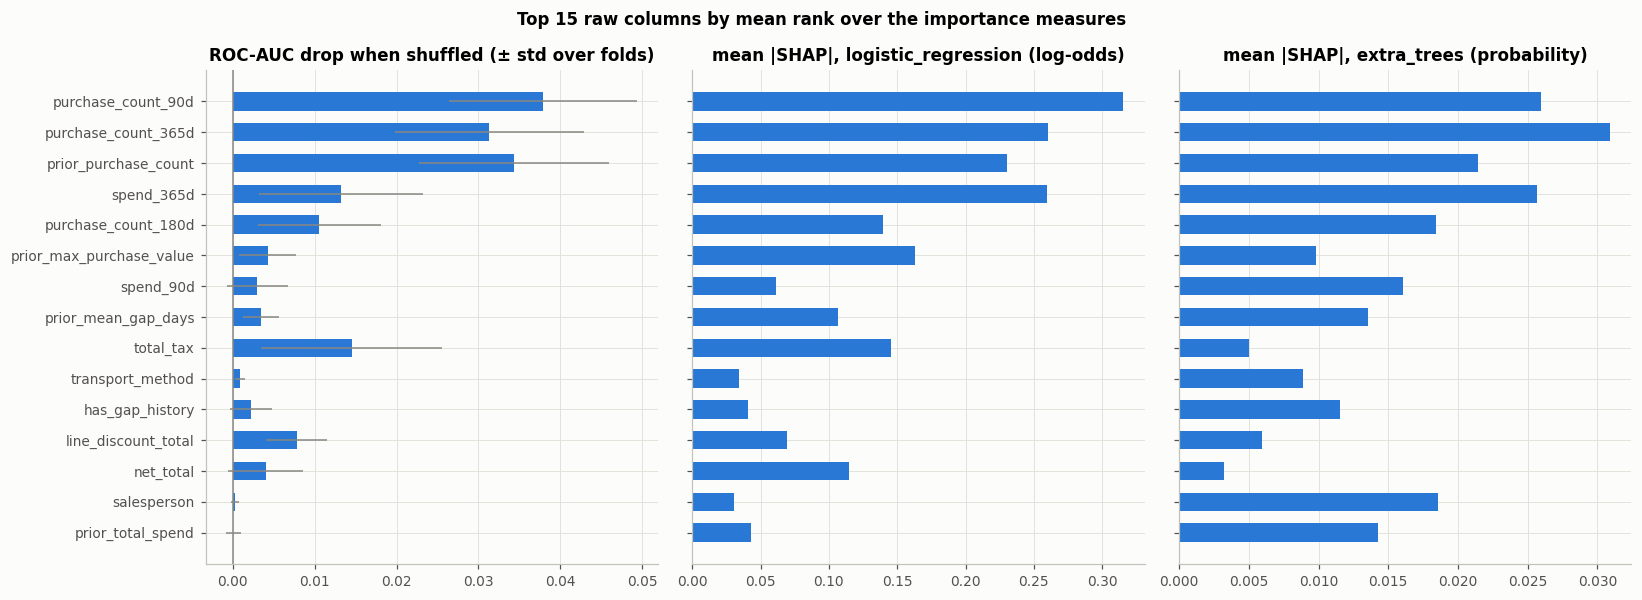

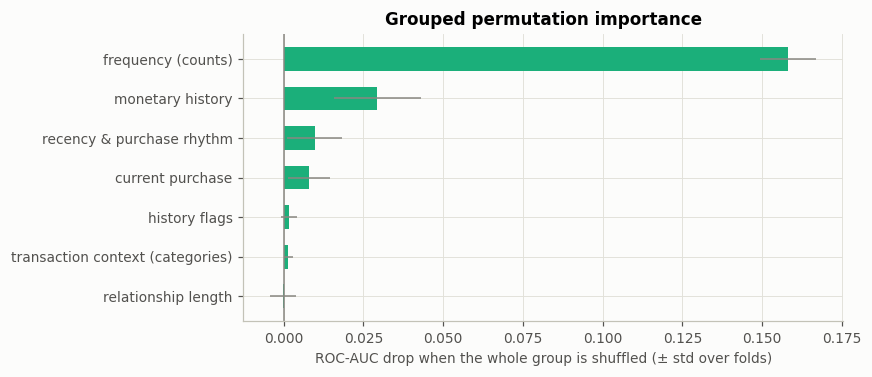

In [27]:
print("Agreement between the measures (Spearman rank correlation over the 34 raw columns):")
display(fmt(importance[measures].corr(method="spearman"), 2))

top = importance.head(15).index[::-1]
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5), sharey=True)
panels = [("permutation: ROC-AUC drop", perm_single["roc_auc drop std"], "ROC-AUC drop when shuffled (± std over folds)"),
          (f"mean |SHAP| {FINAL}", None, f"mean |SHAP|, {FINAL} ({final_unit})"),
          (f"mean |SHAP| {SECOND}", None, f"mean |SHAP|, {SECOND} ({second_unit})")]
for ax, (column, error, title) in zip(axes, panels):
    ax.barh(top, importance.loc[top, column], xerr=None if error is None else error.loc[top],
            color=PALETTE[0], height=0.6, error_kw={"ecolor": GREY, "lw": 1})
    ax.set(title=title)
    ax.axvline(0, color=GREY, lw=1)
plt.suptitle("Top 15 raw columns by mean rank over the importance measures", fontweight="bold")
plt.tight_layout()
plt.show()

group_view = perm_groups.sort_values("roc_auc drop mean")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(group_view.index, group_view["roc_auc drop mean"], xerr=group_view["roc_auc drop std"], color=PALETTE[2],
        height=0.6, error_kw={"ecolor": GREY, "lw": 1})
ax.axvline(0, color=GREY, lw=1)
ax.set(xlabel="ROC-AUC drop when the whole group is shuffled (± std over folds)", title="Grouped permutation importance")
plt.tight_layout()
plt.show()

**What the measures agree on:**

- **Purchase frequency is the dominant driver.** Shuffling the five count columns together costs **0.158 ROC-AUC and 0.11 accuracy** on every fold, five times more than any other group. Next come monetary history (0.029), recency / purchase rhythm (0.010) and the current purchase (0.008). The categories (0.001), the flags (0.002) and tenure on its own (0.000) add almost nothing once the history is known.
- **The top three are the same on every measure:** `purchase_count_90d`, `prior_purchase_count` and `purchase_count_365d`, then `spend_365d`, `purchase_count_180d`, `prior_max_purchase_value` and `total_tax`.
- **Measures broadly agree:** Spearman 0.7–0.8 between ROC-AUC permutation importance, SHAP and the coefficients of logistic regression, and 0.4–0.7 across model families. Extra trees spread importance more evenly over correlated columns and use the categories more (`salesperson`, `document_series`, `transport_method`), yet shuffling those barely moves logistic regression's AUC.

**Where they disagree, and why:**

- **`customer_tenure_days`** has a large mean |SHAP| (0.19 log-odds) but **zero permutation importance**. It works as a *correction* on the counts (the same number of purchases over a longer tenure means a lower purchase rate) and carries no independent signal. The engineered `purchase_rate` of notebook 06 expresses the same idea in one column.
- Correlated columns share credit. Individually, the four count columns lose 0.114 AUC in total; as a group, 0.158. Single-column measures understate a group of near-duplicates.
- **The seven notebook-06 drop candidates** (`warehouse`, `commercial_zone`, `document_series`, `global_discount_total`, `shipping_cost`, `invoice_count_current_purchase`, `is_first_purchase`) are at the bottom on every measure. This confirms notebook 06, but per section 2.1, removing them is a parsimony choice, not a performance gain.

# <font color='#2E86C1' size=6>**10. Drivers of customer return**</font> <a class="anchor" id="drivers"></a>

For the most important columns: **how** the predicted return changes with the value (SHAP dependence, final model, locked test rows) and, as a model-free check, the **observed** repurchase rate by value band on the development set. When both point the same way, the driver is in the data and not an artefact of the model.


[Back to TOC](#toc)

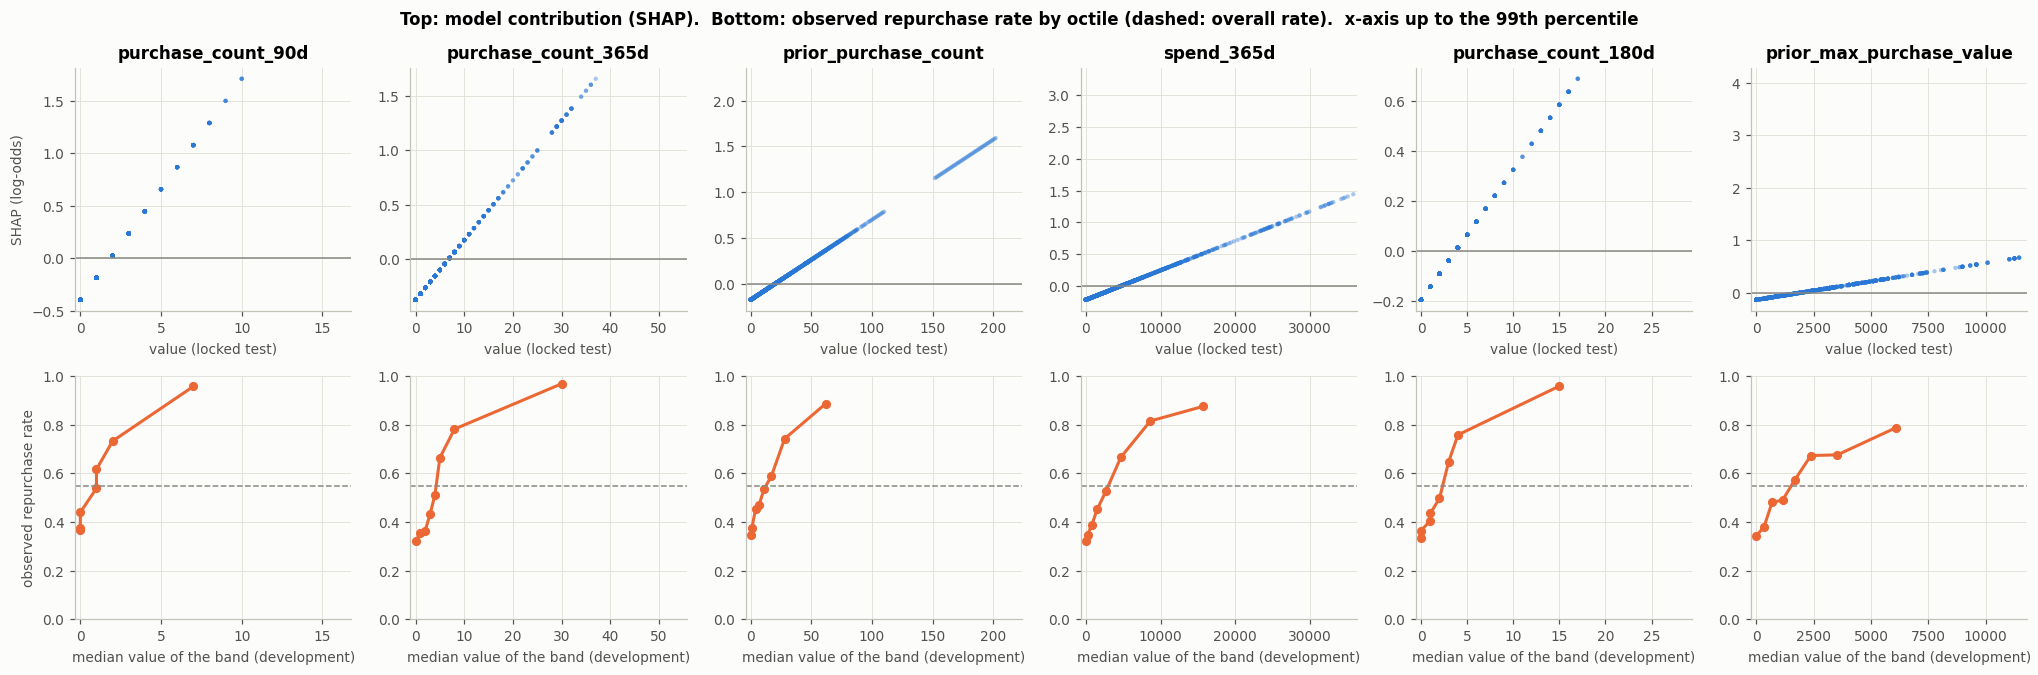

,group,"Spearman(value, SHAP)","Spearman(value, observed return)",mean |SHAP|,higher value means
feature,,,,,
purchase_count_90d,frequency (counts),1.0,0.390,0.315,more likely to return
purchase_count_365d,frequency (counts),1.0,0.424,0.260,more likely to return
prior_purchase_count,frequency (counts),1.0,0.338,0.231,more likely to return
spend_365d,monetary history,1.0,0.394,0.259,more likely to return
purchase_count_180d,frequency (counts),1.0,0.398,0.139,more likely to return
prior_max_purchase_value,monetary history,1.0,0.284,0.163,more likely to return
spend_90d,monetary history,1.0,0.363,0.061,more likely to return
prior_mean_gap_days,recency & purchase rhythm,-1.0,-0.143,0.107,less likely to return
total_tax,current purchase,1.0,0.067,0.145,more likely to return


In [28]:
driver_columns = [c for c in importance.index if c in NUMERIC][:6]
fig, axes = plt.subplots(2, len(driver_columns), figsize=(3.1 * len(driver_columns), 6.2))
for j, column in enumerate(driver_columns):
    k = names.index(column)
    values, contribution = final_expl.data[:, k], final_expl.values[:, k]
    ax = axes[0, j]
    ax.scatter(values, contribution, s=8, alpha=0.4, color=PALETTE[0], edgecolors="none")
    ax.axhline(0, color=GREY, lw=1)
    ax.set(title=column, xlabel="value (locked test)", ylabel=f"SHAP ({final_unit})" if j == 0 else "")

    raw = pd.to_numeric(X_dev[column], errors="coerce").astype(float)
    bands = pd.qcut(raw.rank(method="first"), 8, labels=False)
    rates = pd.DataFrame({"value": raw, "y": y_dev, "band": bands}).groupby("band").agg(value=("value", "median"), rate=("y", "mean"))
    ax = axes[1, j]
    ax.plot(rates["value"], rates["rate"], marker="o", ms=5, color=PALETTE[1])
    ax.axhline(y_dev.mean(), color=GREY, ls="--", lw=1)
    ax.set(xlabel="median value of the band (development)", ylabel="observed repurchase rate" if j == 0 else "", ylim=(0, 1))
    upper = np.nanpercentile(np.concatenate([values, raw.dropna().to_numpy()]), 99)
    for row in (0, 1):
        axes[row, j].set_xlim(-0.02 * upper, upper * 1.05)
plt.suptitle("Top: model contribution (SHAP).  Bottom: observed repurchase rate by octile (dashed: overall rate).  "
             "x-axis up to the 99th percentile",
             fontweight="bold")
plt.tight_layout()
plt.show()

direction = pd.DataFrame([{
    "feature": c,
    "group": importance.loc[c, "group"],
    "Spearman(value, SHAP)": spearmanr(final_expl.data[:, names.index(c)], final_expl.values[:, names.index(c)]).statistic,
    "Spearman(value, observed return)": spearmanr(pd.to_numeric(X_dev[c], errors="coerce").astype(float), y_dev, nan_policy="omit").statistic,
    "mean |SHAP|": importance.loc[c, f"mean |SHAP| {FINAL}"],
} for c in importance.index[:12]]).set_index("feature")
direction["higher value means"] = np.where(direction["Spearman(value, SHAP)"] > 0, "more likely to return", "less likely to return")
fmt(direction, 3)

In [29]:
# categorical drivers: the repurchase rate of each category (development set, categories with >= 30 purchases)
cat_rows = []
for column in recipe["categorical_features"]:
    rates = pd.DataFrame({"category": X_dev[column].astype(str), "y": y_dev}).groupby("category")["y"].agg(["mean", "size"])
    rates = rates[rates["size"] >= 30]
    cat_rows.append({"column": column, "categories (≥ 30 purchases)": len(rates),
                     "lowest rate": rates["mean"].min(), "highest rate": rates["mean"].max(),
                     "spread": rates["mean"].max() - rates["mean"].min(),
                     "mean |SHAP|": importance.loc[column, f"mean |SHAP| {FINAL}"],
                     "permutation ROC-AUC drop": importance.loc[column, "permutation: ROC-AUC drop"]})
fmt(pd.DataFrame(cat_rows).set_index("column").sort_values("mean |SHAP|", ascending=False), 3)

,categories (≥ 30 purchases),lowest rate,highest rate,spread,mean |SHAP|,permutation ROC-AUC drop
column,,,,,,
transport_method,26,0.225,0.981,0.756,0.034,0.001
salesperson,6,0.367,0.615,0.248,0.031,0.000
payment_type,4,0.376,0.957,0.580,0.011,0.000
document_series,3,0.517,0.561,0.044,0.001,-0.000
commercial_zone,3,0.349,0.554,0.205,0.000,-0.000
warehouse,1,0.549,0.549,0.000,0.000,0.000


**Drivers of customer return.** Both views agree in direction for every top feature: the model's contribution (SHAP) and the observed repurchase rate rise together.

1. **Recent activity is the strongest signal.** Customers with **no purchase in the previous 90 days return 37–44 %** of the time. With 2 recent purchases the rate is **73 %**, and the most active octile returns 96 % of the time. The 365-day count shows the same pattern (32 % → 97 %). A customer who has gone quiet for a quarter is the clearest warning sign.
2. **Loyalty built over time.** The number of previous purchases (35 % → 89 %) and the largest previous purchase (34 % → 79 %) both raise the chance of return. High-value customers return more, partly because they also buy more often; the model gives `spend_365d` extra weight on top of the counts.
3. **Purchase rhythm.** Customers who usually buy every **~24 days return 85 %** of the time, against **33 % for a ~150-day rhythm** and 38 % for customers without a rhythm yet (0 or 1 previous purchase). The 90-day window catches fast-cycle buyers almost automatically.
4. **Tenure.** On its own, a very new customer (under ~4 months) returns less (43 % vs about 58 %). For a *given* number of purchases, though, a longer relationship lowers the probability. What matters is the **purchase rate**, not the age of the account.
5. **The current purchase.** A large invoice (`net_total`, high `spend_30d`) lowers the probability given the history, consistent with stocking up. A higher tax amount for the same net value raises it, a VAT-band / product-mix effect (notebook 06, section 6.1). Both effects are real but small.
6. **Transaction context.** Transport method and payment type have very different raw rates (22–98 % and 38–96 % between categories), but they add almost nothing once the purchase history is known. They proxy the type of customer rather than cause a return. Warehouse and commercial zone carry no signal.

**For the business:**

- The model mostly measures **how active the customer has been recently relative to their own history**.
- The most useful retention target is the **"slipping regular"** (like the borderline customer of section 8): a long, valuable history, but no purchase in the last 90 days.
- One- or two-time buyers with long gaps rarely return and are expensive to win back.
- Large one-off purchases are followed by a pause, not necessarily by churn.

These are associations in historical data, not causal effects. A pilot with a control group (section 7) would show whether an incentive actually changes behaviour for these profiles.

# <font color='#2E86C1' size=6>**11. Summary**</font> <a class="anchor" id="summary"></a>

| To-do | Outcome |
|---|---|
| Baseline model | Majority class 0.553; recency rule 0.668 (ROC-AUC 0.663); RFM logistic regression 0.663 (ROC-AUC 0.756) |
| Preprocessing pipeline | The config-driven recipe (row-bounded median imputation, target encoding, standard scaling, missing indicator, flags) inside one `Pipeline`, re-fitted per fold. No missing values on any split. The notebook-06 reduced list is not decisively better for any model → full recipe kept |
| LR, k-NN, DT, RF, extra trees, HGB, XGBoost | Untuned: none beats logistic regression; boosters and forests overfit strongly (gap 0.14–0.25) |
| Hyperparameter tuning | Optuna (40 trials) + nested temporal CV (20 trials per outer fold). It regularises every model; gains of +0.005 to +0.030 accuracy, largest for the tree and the boosters |
| Compare metrics | Nested CV on 9 metrics. Six models tied on accuracy (0.703–0.713); extra trees best on ROC-AUC / Brier (decisive but < 0.01); decision tree decisively worse |
| **Final model** | **Tuned logistic regression** (`C = 0.024`, balanced class weights). Nested CV accuracy 0.713 / ROC-AUC 0.775; **locked test 0.704 / 0.784** (+0.10 over the floor, +0.023 over the recency rule) |
| Threshold & business | 0.5 for accuracy (flat optimum). For retention, threshold `1 − C/(uV)` ≈ 0.52 with the default assumptions; €6.5k per 1,000 purchases on the locked test vs €5.2k for the rule and −€8.1k for contacting everyone. The lowest-scored 20 % hold 37 % of non-returners. The decision depends more on the incentive cost and uplift than on the model, so measure the uplift first |
| Explainability | SHAP (exact for the linear model) and LIME agree on direction for every shared feature; three customer profiles explained |
| Feature importance | Frequency counts dominate (grouped AUC drop 0.158), then monetary history, rhythm and the current purchase. Categories, flags and the notebook-06 drop candidates add almost nothing |
| Drivers of return | Recent activity (90 / 365-day counts), long and valuable history, a short purchase rhythm. Negative: long gaps, low purchase rate for the tenure, large one-off purchases |

**Not changed by this notebook** (decisions for the pipeline, `config.yaml`):

- `classification.model` is still the untuned logistic regression. The tuned settings (`C: 0.0245, class_weight: balanced`) are 0.005 accuracy better in nested CV, but within noise; adopting them is a one-line change.
- The notebook-06 feature drop list is not applied (no decisive gain).
- The Kaggle threshold stays at 0.5.

**Limits and next steps:**

- The return rate drifts upwards (55 % → 60 %). Re-check the threshold or intercept on the latest labelled period before each use.
- Logistic regression extrapolates linearly on extreme gap values (section 8.2). A log transform or cap of `prior_mean_gap_days` is a cheap fix to test.
- The campaign economics rest on two assumptions (`C`, `u`) that only a pilot with a control group can measure.


[Back to TOC](#toc)